
1. LOADING FILES
  mounting Google Drive (approve the pop-up) ...
Mounted at /content/drive
  Drive folder not found: /content/drive/MyDrive/warehouse_data  (create it and put the CSVs there)
  downloading the public dataset from Mendeley Data ...
  (Mendeley download failed: HTTP Error 403: Forbidden)
Missing files: ['Product.csv', 'Customer_Order.csv', 'Picking_Wave.csv', 'Storage_Location.csv', 'Support_Points_Navigation.csv', 'Random_Storage.csv', 'Class_Based_Storage.csv', 'Dedicated_Storage.csv', 'Hybrid_Storage.csv']
Please select them in the upload dialog ...


Saving Class_Based_Storage.csv to Class_Based_Storage.csv
Saving Customer_Order.csv to Customer_Order.csv
Saving Dedicated_Storage.csv to Dedicated_Storage.csv
Saving Hybrid_Storage.csv to Hybrid_Storage.csv
Saving Picking_Wave.csv to Picking_Wave.csv
Saving Product.csv to Product.csv
Saving Random_Storage.csv to Random_Storage.csv
Saving Storage_Location.csv to Storage_Location.csv
Saving Support_Points_Navigation.csv to Support_Points_Navigation.csv
  loaded Product.csv                      delimiter=';' rows=208
  loaded Customer_Order.csv               delimiter=';' rows=122,370
  loaded Picking_Wave.csv                 delimiter=';' rows=215,192
  loaded Storage_Location.csv             delimiter=',' rows=2,292
  loaded Support_Points_Navigation.csv    delimiter=';' rows=44
  loaded Random_Storage.csv               delimiter=',' rows=2,292
  loaded Class_Based_Storage.csv          delimiter=';' rows=2,341
  loaded Dedicated_Storage.csv            delimiter=';' rows=2,340
  loaded 

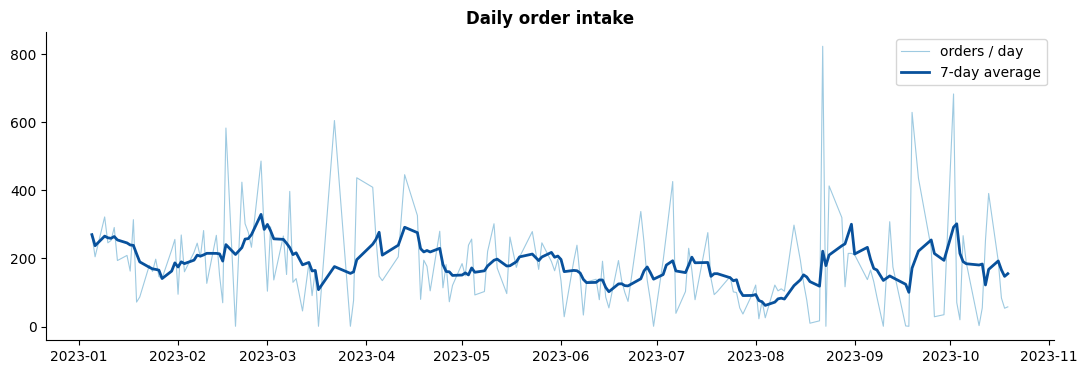

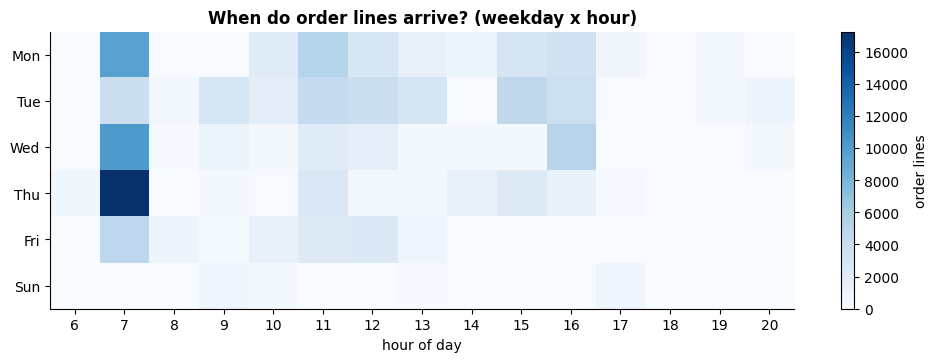

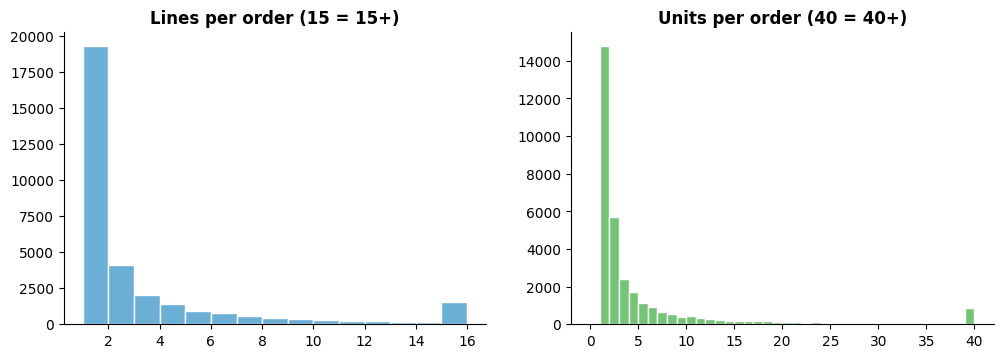

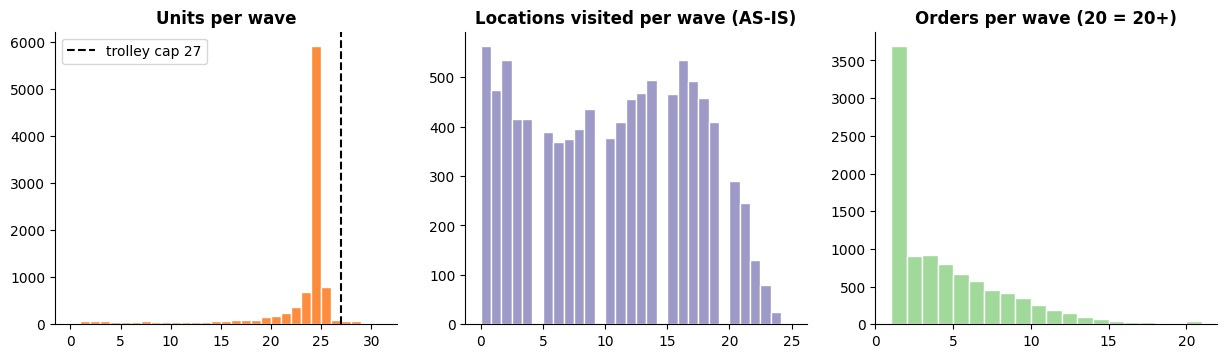

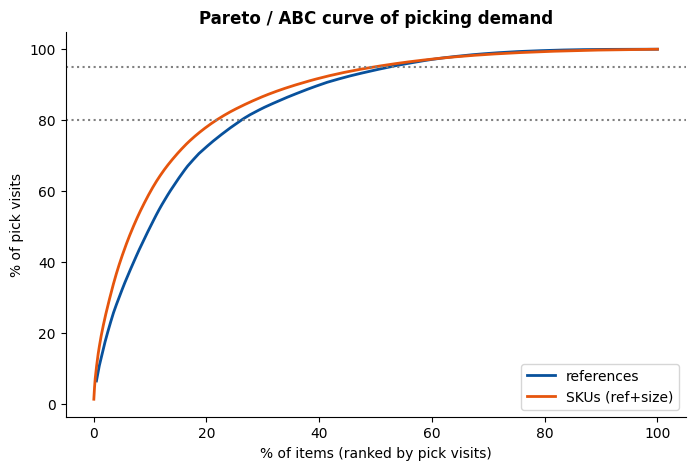

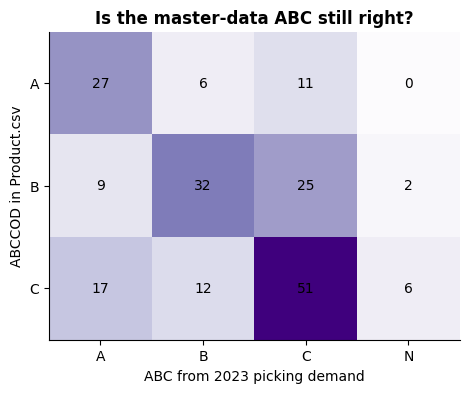

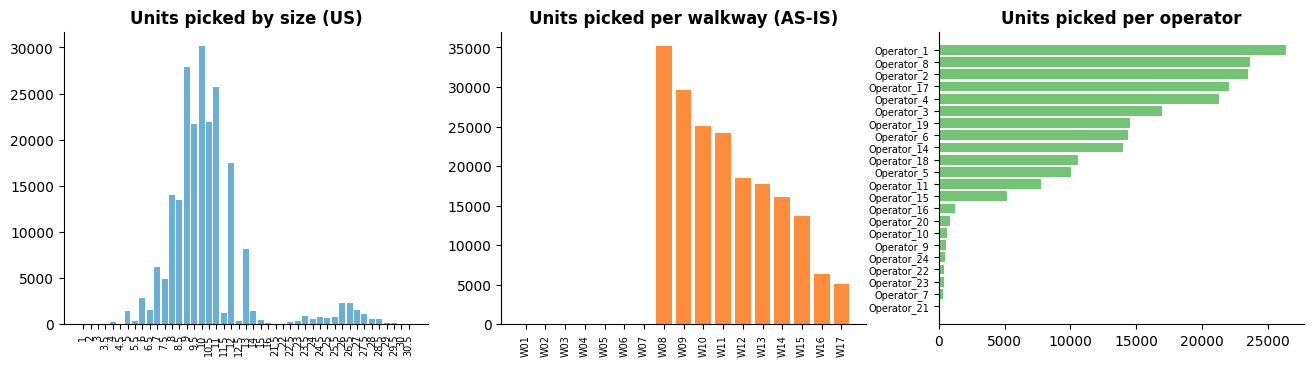

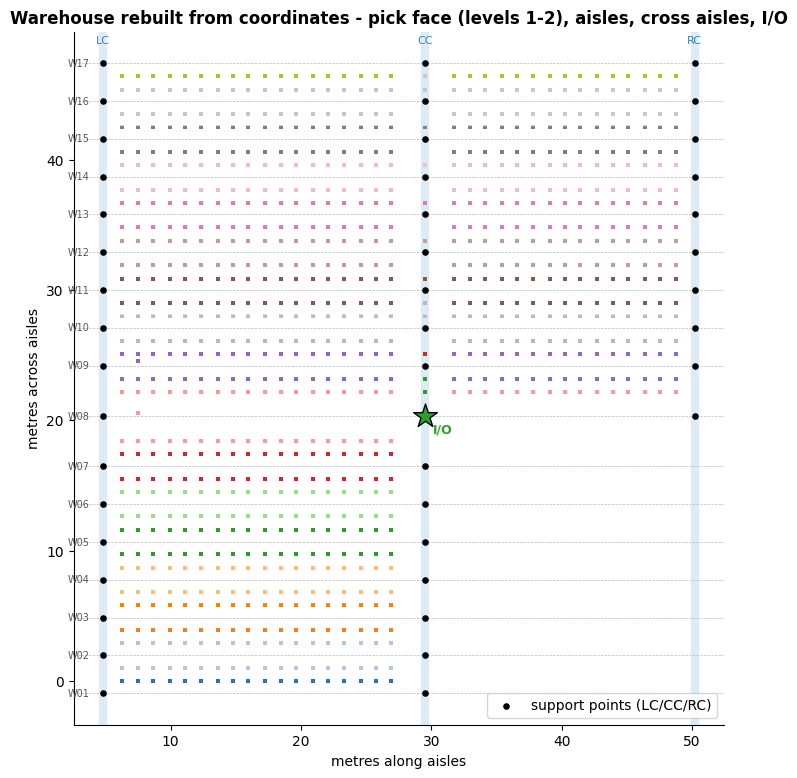

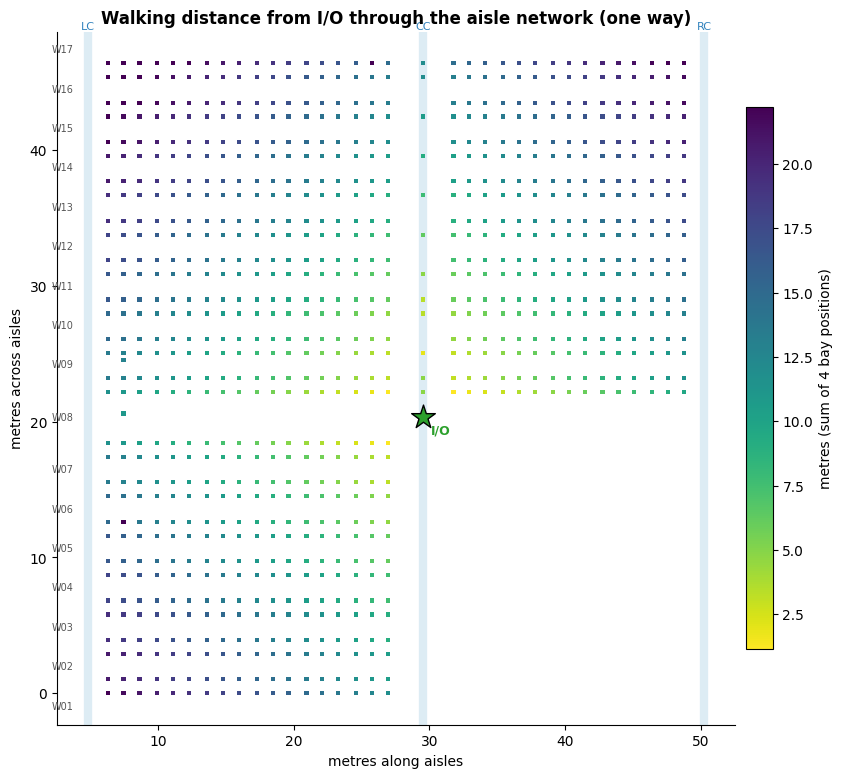


5b. STORAGE POLICIES AND NEW SLOTTING DESIGN
  88.7% of pick rows find their exact SKU (reference+size) in Random storage -> slotting/matching key = SKU
  inventory preserved from Random: 41,256 units of 2,980 items
  Optimised-COI: forward-zone re-slotting moves 6,728 units (16.3% of stock)
  Optimised-COI: 1,769 items on pick face using 3,372 primary slots of 30,456
  Optimised-FAMILY: forward-zone re-slotting moves 6,738 units (16.3% of stock)
  Optimised-FAMILY: 1,769 items on pick face using 3,372 primary slots of 30,456
          scenario  mean_one_way_dist_per_pick_m  share_picks_within_15m  exact_share
AS-IS (historical)                         21.00                    0.30          NaN
            Random                         16.92                    0.49         0.89
        ClassBased                         13.51                    0.66         0.92
         Dedicated                         14.86                    0.56         0.93
            Hybrid                   

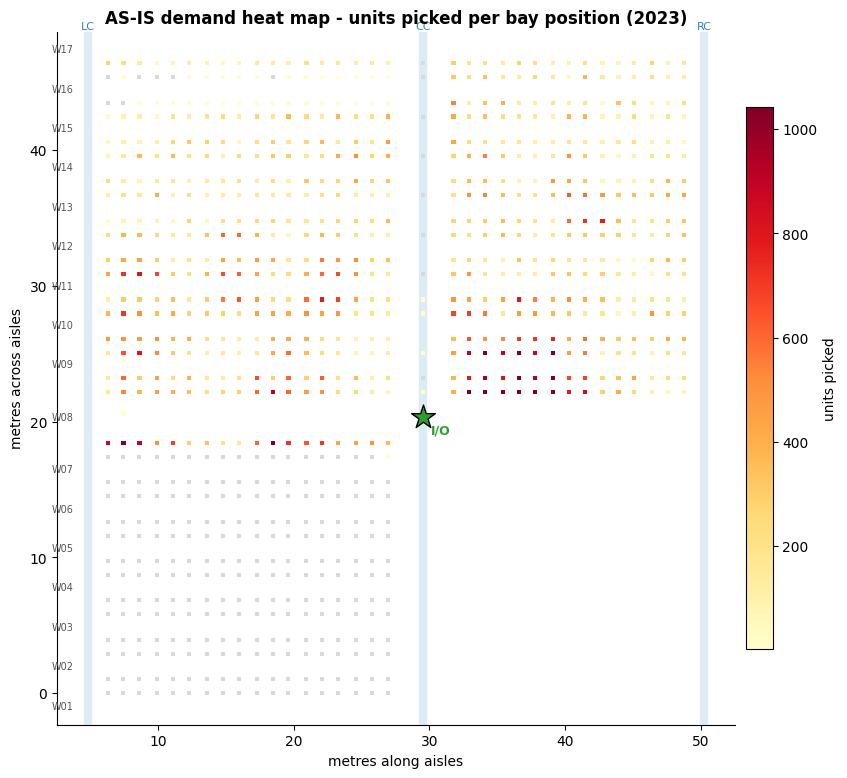

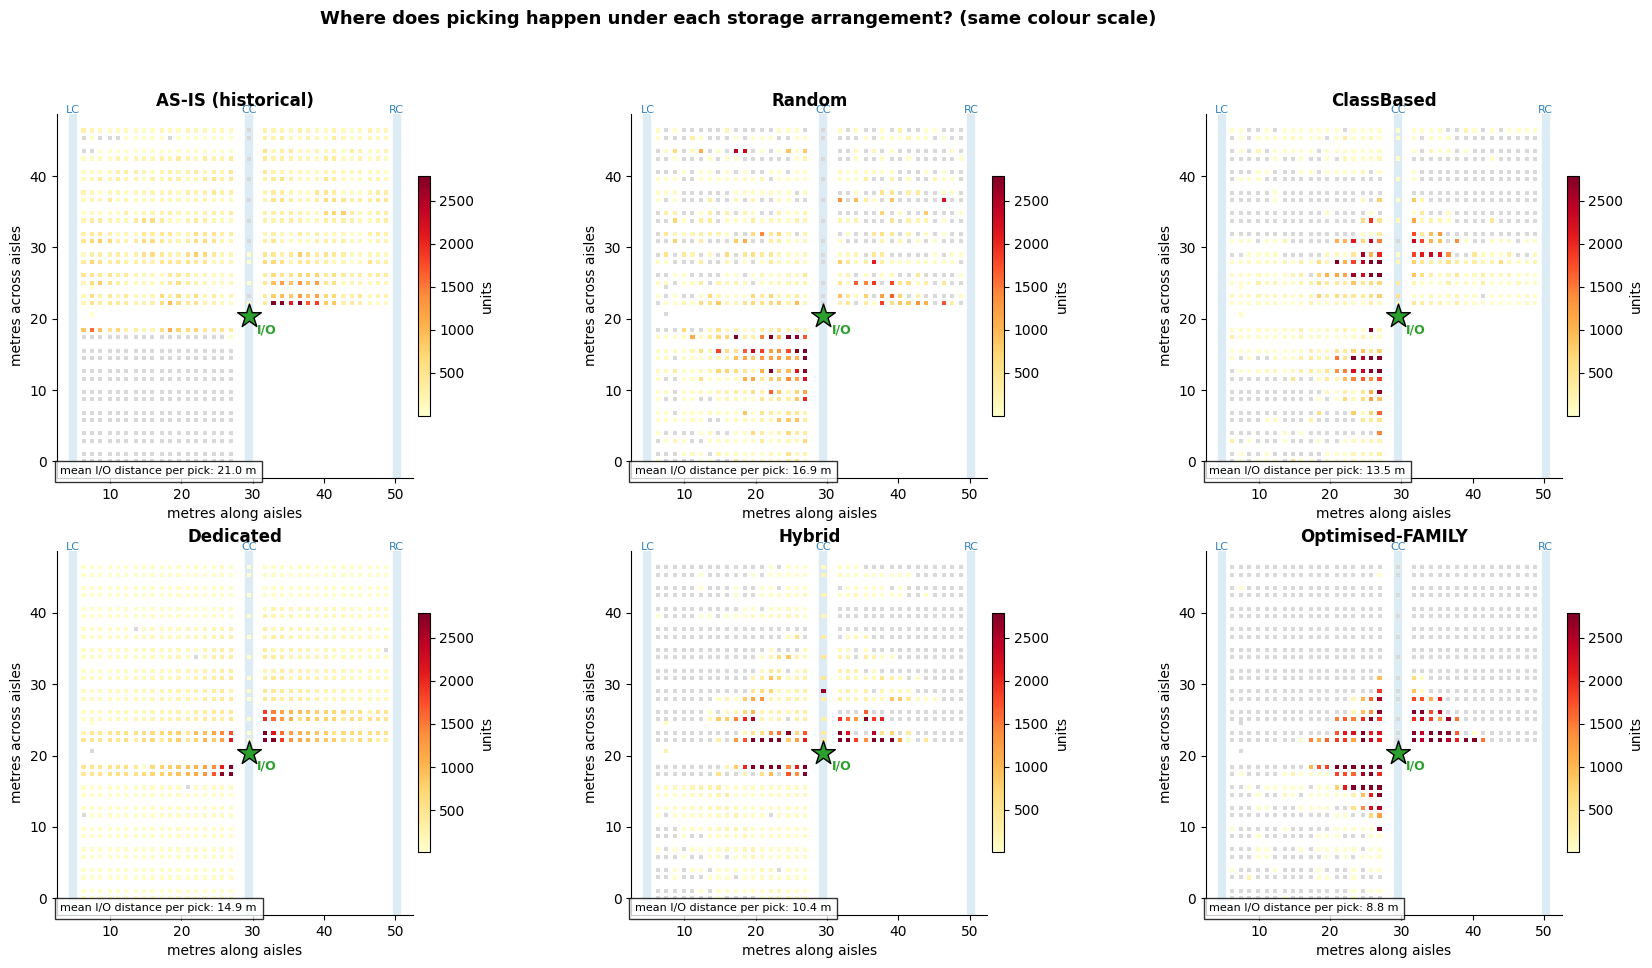

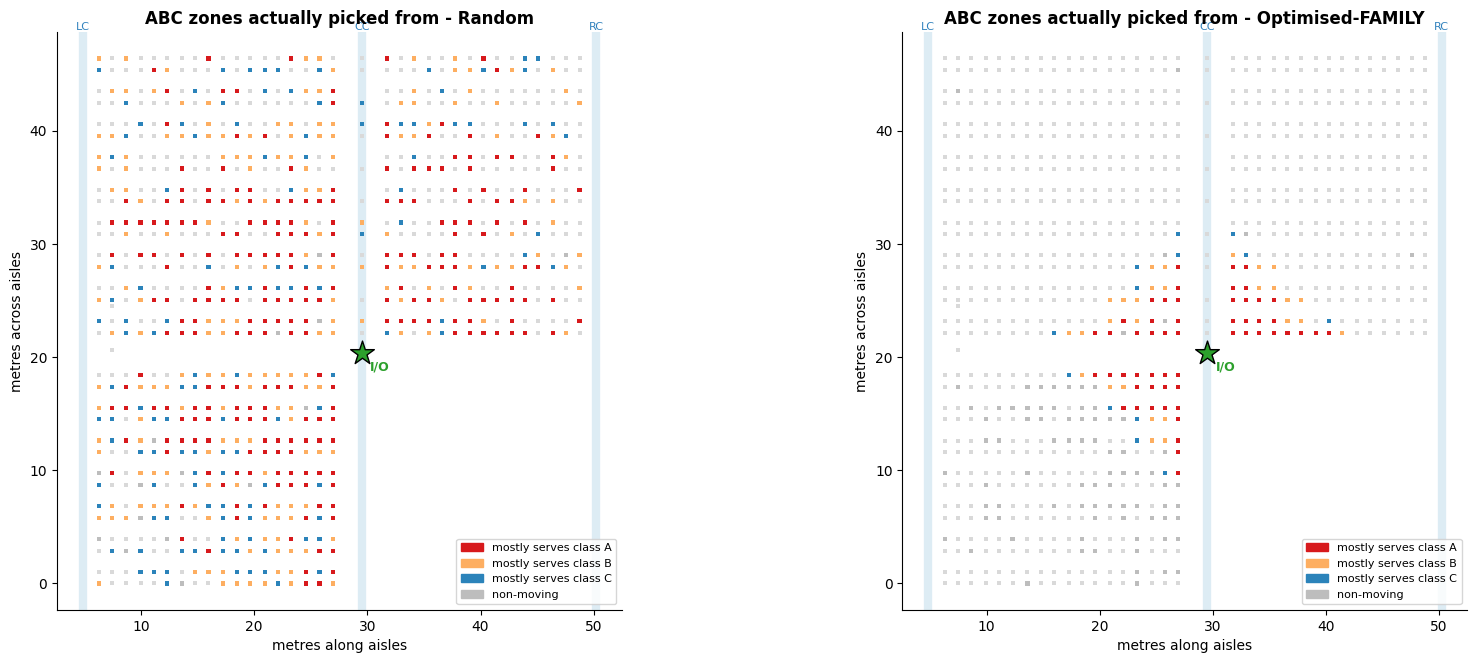

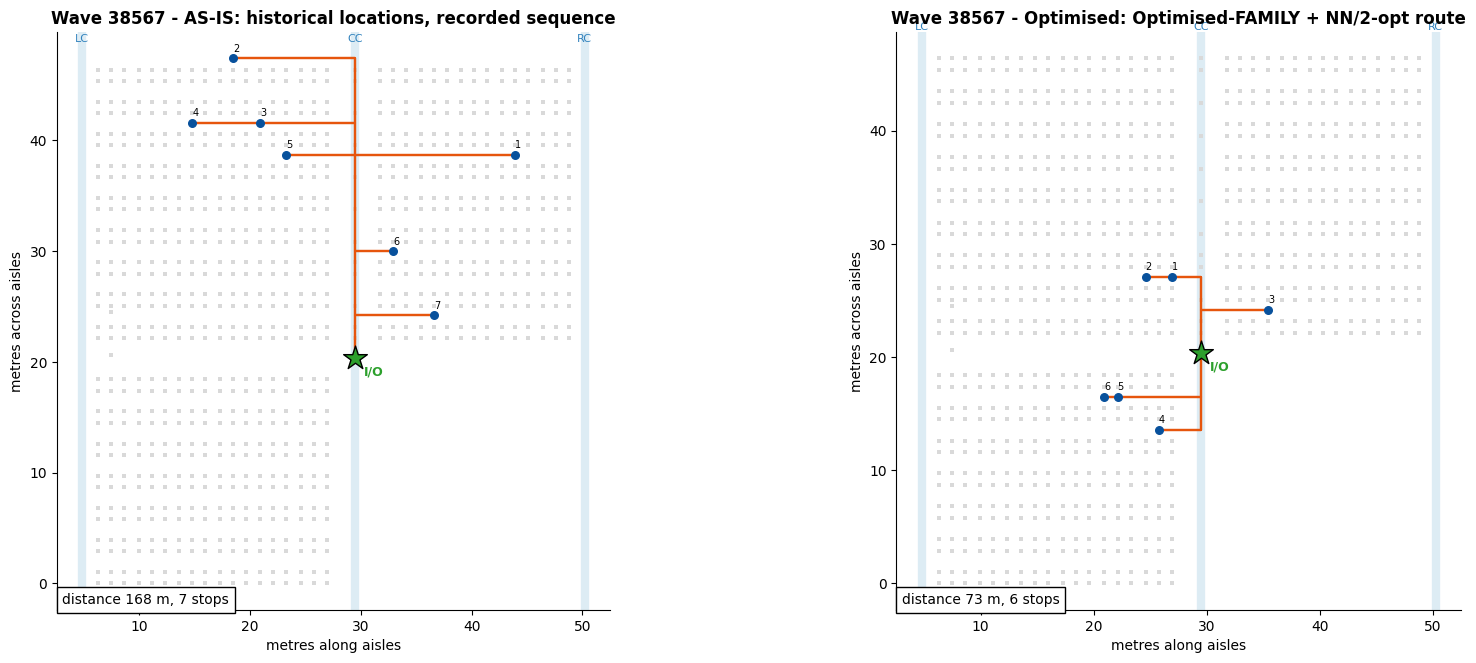

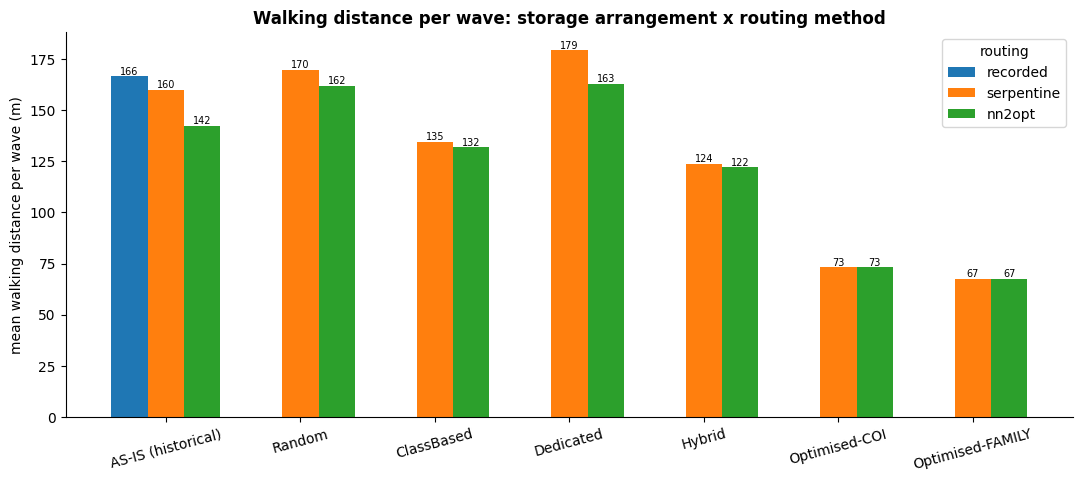

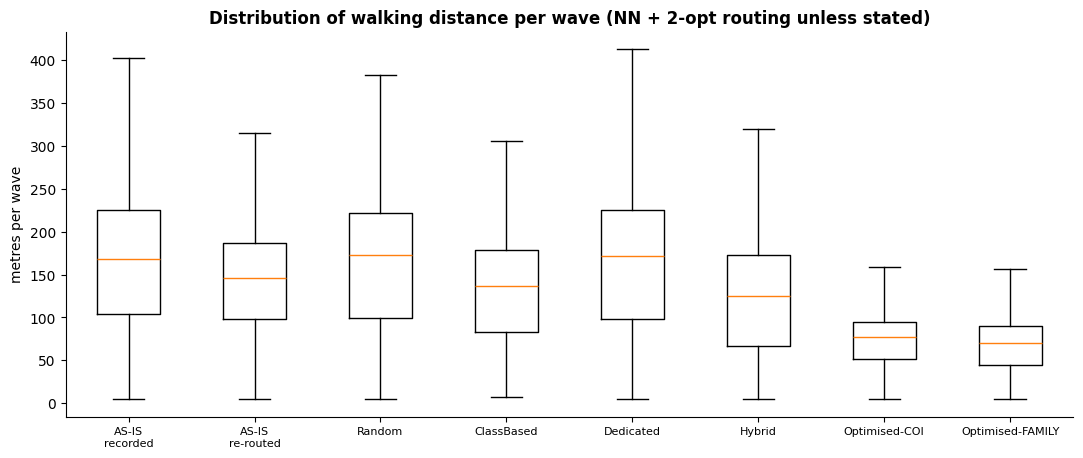

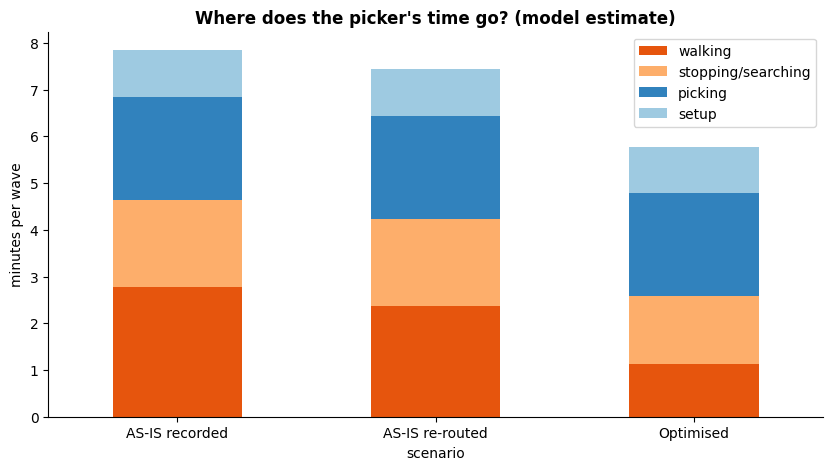

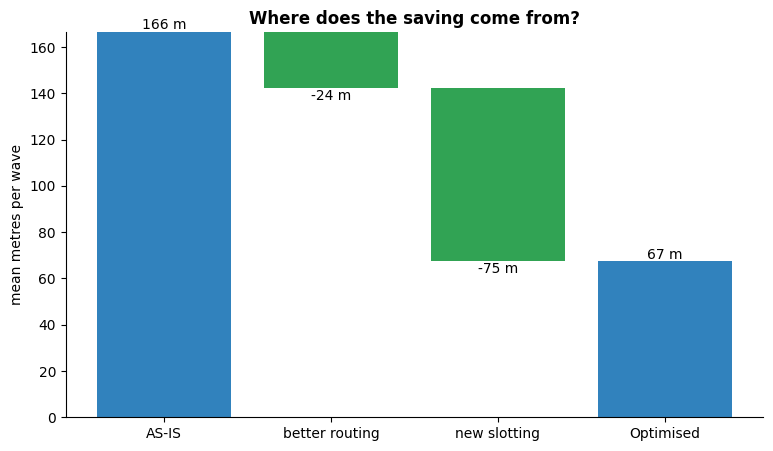

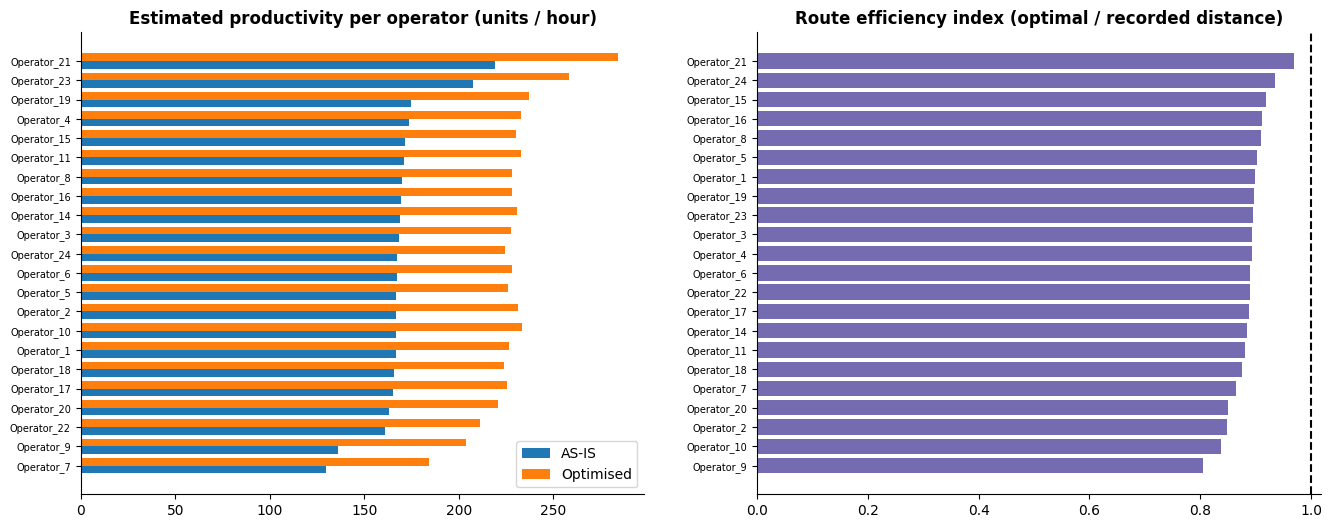

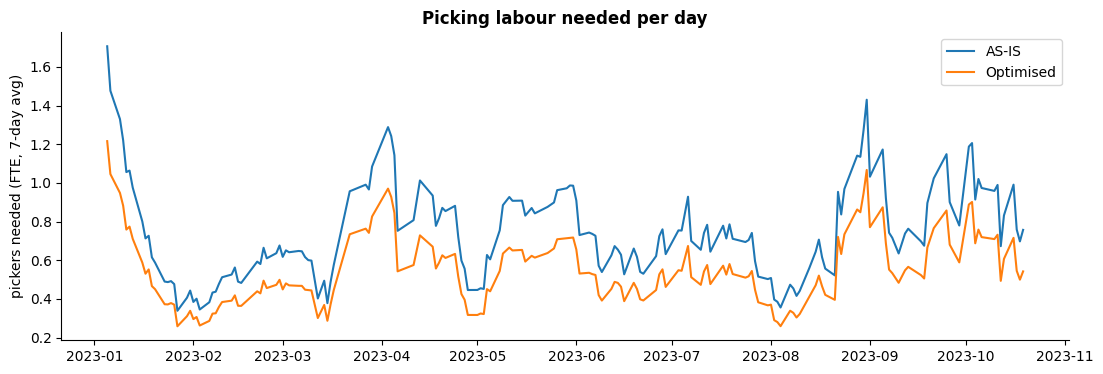

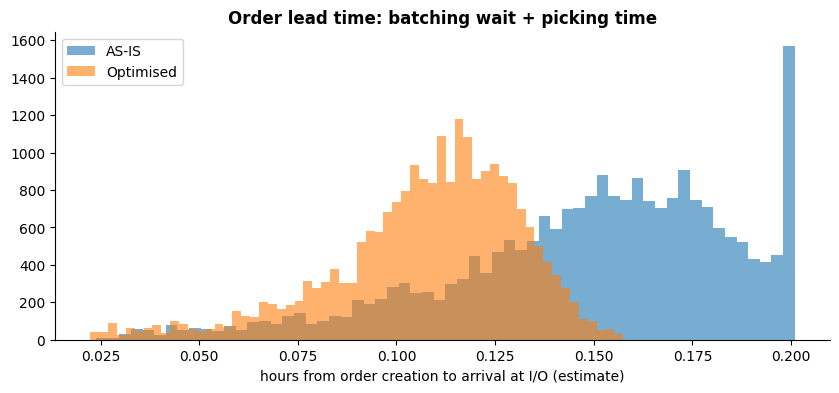

  figures saved in /content/outputs/figures

7b. TIME VARIATION ACROSS ARRANGEMENTS


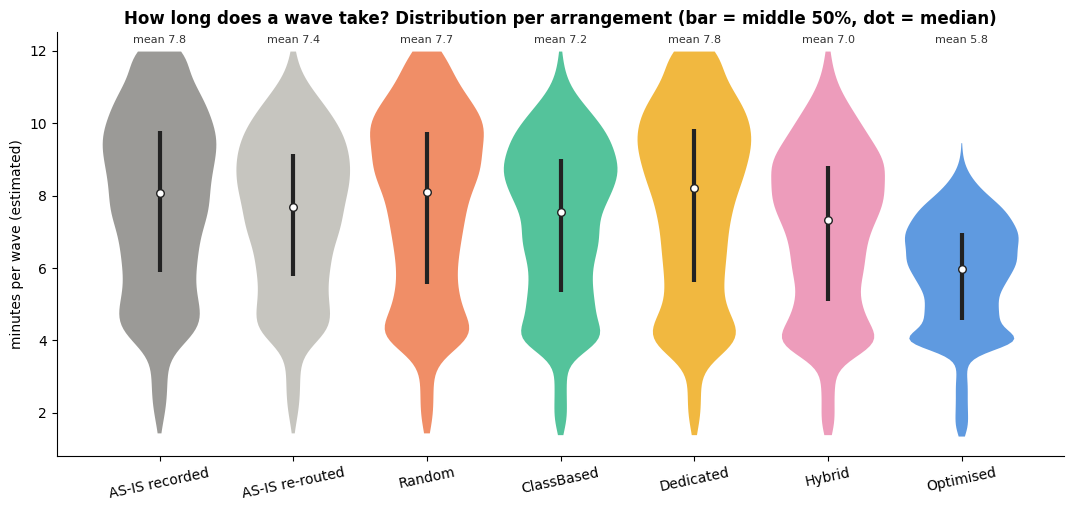

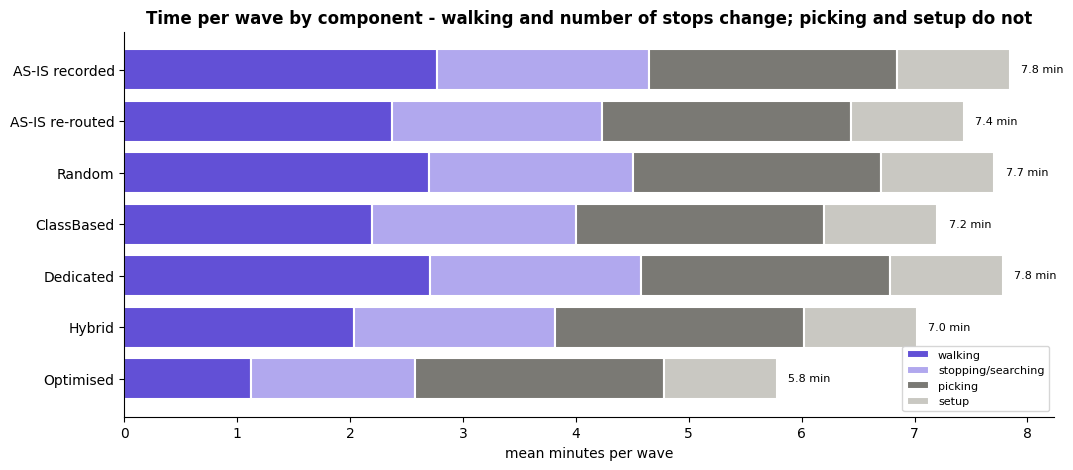

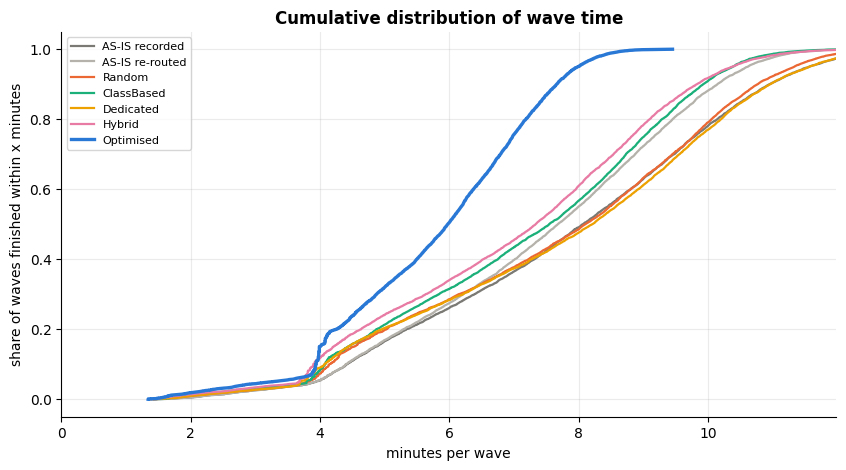

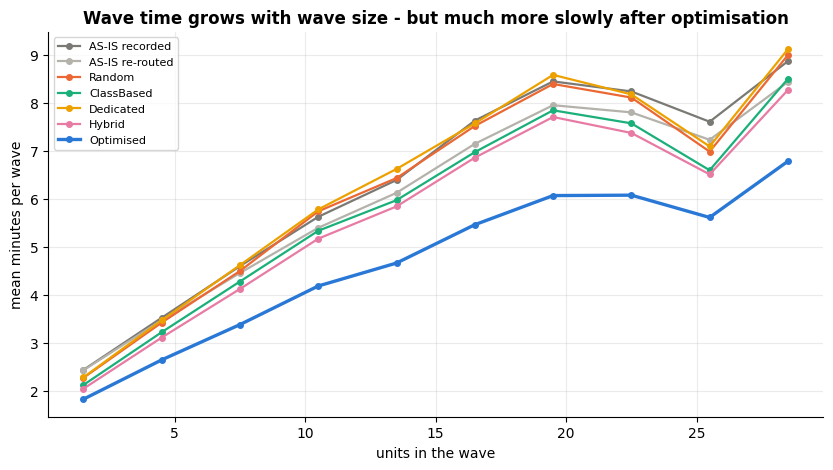

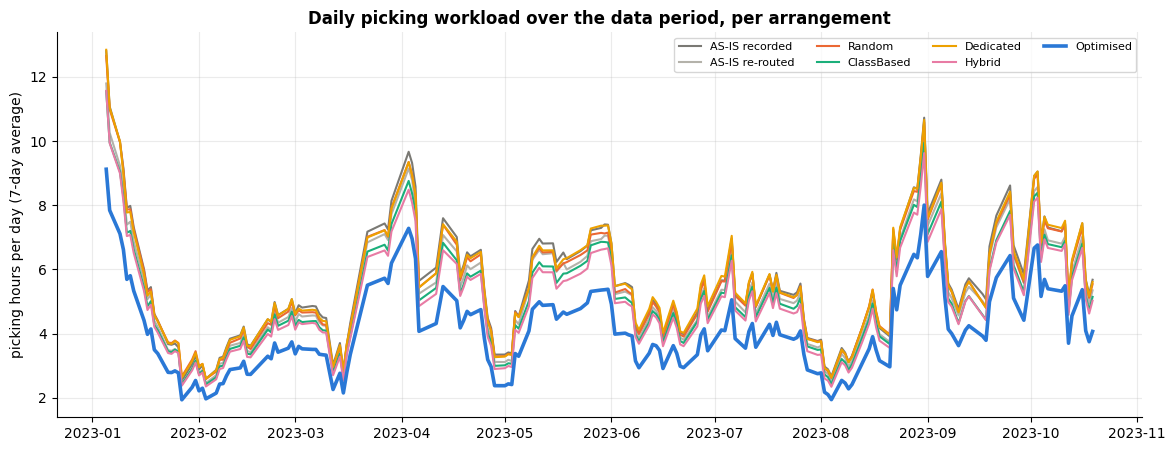

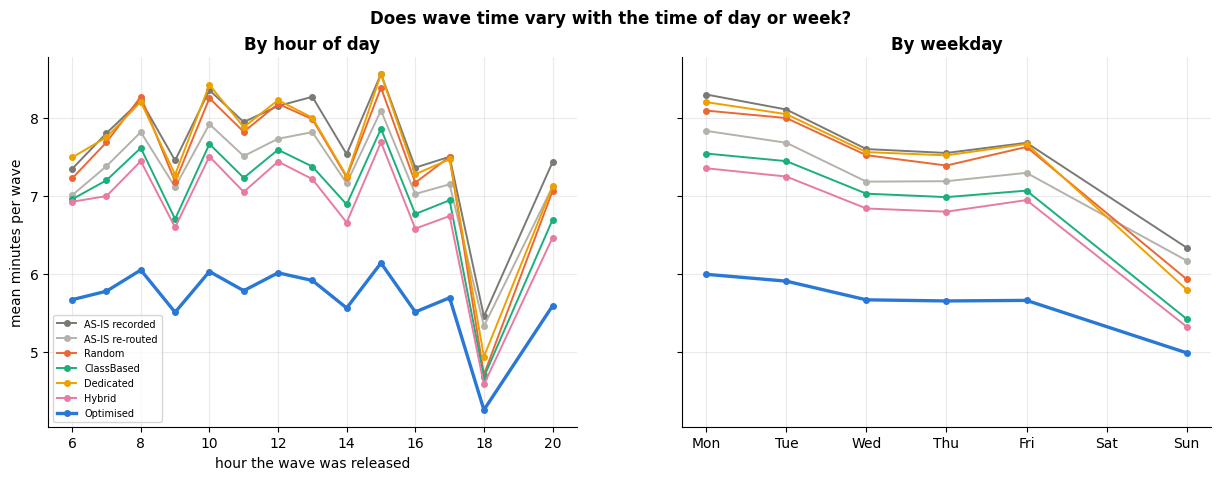

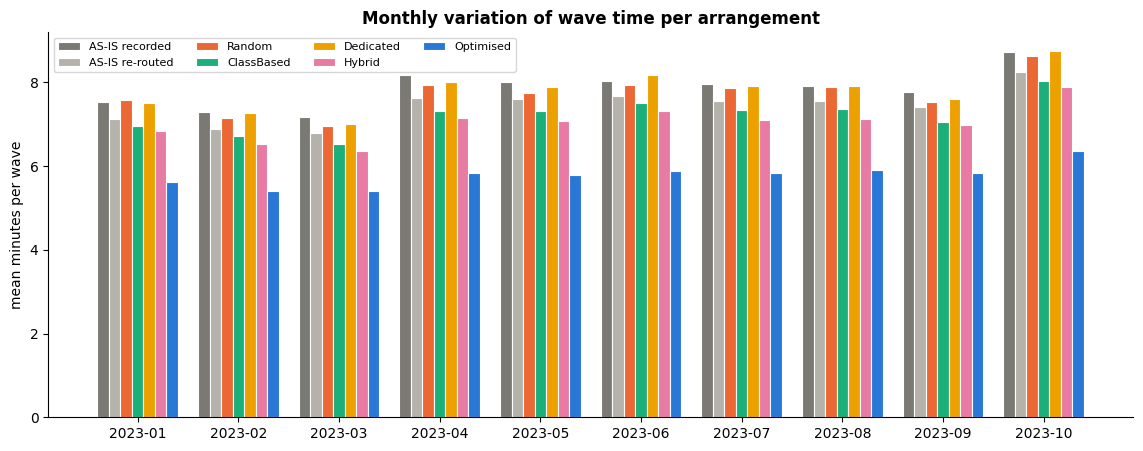

                 mean  median   p90   CV  vs_AS-IS_%
arrangement                                         
AS-IS recorded   7.85    8.06 10.95 0.32        0.00
AS-IS re-routed  7.44    7.68 10.14 0.29       -5.21
Random           7.71    8.10 10.77 0.33       -1.79
ClassBased       7.20    7.54  9.93 0.31       -8.23
Dedicated        7.78    8.21 10.96 0.33       -0.81
Hybrid           7.02    7.33  9.83 0.32      -10.54
Optimised        5.78    5.98  7.66 0.27      -26.35

8. EXCEL + CSV OUTPUTS
  wrote 01_Analysis_Tables.xlsx
  re-shuffle plan: 6,738 unit moves (16.3% of stock) into 186 forward-zone locations; phase 1 (class A) = 3,818 moves
  wrote 02_New_Slotting_Plan.xlsx

8b. FLOOR PLANS PER LEVEL + CAD (DXF/DWG)
  12 floor-plan PDFs (+PNG) in figures/floor_plans; 12 CAD files in cad/
  DWG not produced here (needs the free ODA File Converter). Open the .dxf in AutoCAD / DWG TrueView and 'Save As' DWG, or batch-convert the cad folder with ODA File Converter on your laptop.
  wrote

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# =============================================================================
# 0. CONFIGURATION  -  change values here, not inside the code
# =============================================================================
import os, re, io, csv, sys, time, math, json, shutil, warnings
from collections import defaultdict, Counter

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")
try:
    from IPython import get_ipython
    IN_NOTEBOOK = get_ipython() is not None and hasattr(get_ipython(), "kernel")
except Exception:
    IN_NOTEBOOK = False

import matplotlib
if not IN_NOTEBOOK:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

BASE = "/content" if os.path.isdir("/content") else os.getcwd()

CONFIG = dict(
    # ---- input / output ----------------------------------------------------
    DATA_DIRS=[os.path.join(BASE, "data"), BASE, os.getcwd()],
    # If Colab's upload button fails ("Unable to read file"), put the CSVs (or the
    # dataset .zip) in a Google Drive folder and write its name here, e.g. "warehouse_data".
    # The script mounts Drive and reads from /content/drive/MyDrive/<folder>.
    DRIVE_FOLDER="warehouse_data",
    TRY_MENDELEY_DOWNLOAD=True,     # last resort: download the public dataset zip (CC BY 4.0)
    ODA_CONVERTER_PATH=None,        # path to ODAFileConverter (free) to also write .dwg; DXF is always written
    MENDELEY_ZIP_URL="https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/pf2w725pw3-1.zip",
    OUTPUT_DIR=os.path.join(BASE, "outputs"),
    SHOW_FIGURES=True,              # show charts inline when using %run in Colab

    # ---- warehouse geometry (case facts, Data in Brief 61:111837) ----------
    IO_SUPPORT_LABEL="CC-08",       # I/O depot = central corridor at aisle H (green box on the CAD)
    IO_XY_DATA_UNITS=None,          # override, e.g. (x, y) in the CSV's units
    AXIS_SCALE="auto",              # "auto" (calibrate each axis), "same" (one scale), "manual"
    BAY_LENGTH_M=3.66,              # one rack bay along the aisle (144 in)
    AISLE_PITCH_M=2.90,             # rack-row + aisle pitch across aisles (56" + 58")
    MANUAL_M_PER_UNIT_ALONG=0.0254, # used if AXIS_SCALE="manual" or calibration fails
    MANUAL_M_PER_UNIT_CROSS=0.0254,
    PICK_LEVELS=(1, 2),             # manual picking levels
    RESERVE_LEVELS=(3, 4),          # forklift replenishment levels
    SLOTS_PER_LOCATION=18,          # capacity of a storage location
    TROLLEY_CAPACITY=27,            # max items per wave

    # ---- time model (no timestamps in the data -> engineering standards) ----
    WALK_SPEED_MPS=1.0,             # walking with a trolley (literature 0.8-1.2 m/s)
    TIME_PER_STOP_S=10.0,           # stop, find location, read label
    TIME_PER_UNIT_S=6.0,            # grab one box and put it on the trolley
    WAVE_SETUP_S=60.0,              # take pick list + trolley, drop at staging

    # ---- demand / slotting -------------------------------------------------
    SIZE_DECIMAL_FIX=True,          # 85 -> 8.5, 105 -> 10.5 (size > 20 is divided by 10)
    MATCH_LEVEL="auto",             # "sku" (reference+size), "reference", or "auto"
    AUTO_SKU_MATCH_THRESHOLD=0.60,  # in "auto": use SKU level if >= 60 % of picks match exactly
    ABC_CUTS=(0.80, 0.95),          # cumulative share of pick visits for A / B
    SLOTTING_DEMAND="wave_visits",  # "wave_visits" (travel driver) or "units"
    PICKFACE_DAYS_OF_COVER=2.0,     # pick-face stock per SKU >= this many days of demand
    TRAIN_FRACTION=0.70,            # design on first 70 % of waves, test on the rest
    BASELINE_INVENTORY="Random",    # inventory to preserve and re-shuffle (current policy)
    DEFAULT_WAVES_PER_DAY=40,       # only used if order dates are unavailable

    # ---- routing -----------------------------------------------------------
    TWO_OPT_MAX_PASSES=10,
    MAX_WAVES=None,                 # e.g. 1500 for a quick trial run; None = all waves

    # ---- economics ---------------------------------------------------------
    SHIFT_HOURS=7.5,                # productive picking hours per FTE per day
    LABOR_COST_PER_HOUR=25.0,
    CURRENCY="CAD",
    WORKING_DAYS_PER_YEAR=250,
    RANDOM_SEED=42,
)

FILES = {
    "product": "Product.csv",
    "orders": "Customer_Order.csv",
    "picking": "Picking_Wave.csv",
    "locations": "Storage_Location.csv",
    "support": "Support_Points_Navigation.csv",
    "Random": "Random_Storage.csv",
    "ClassBased": "Class_Based_Storage.csv",
    "Dedicated": "Dedicated_Storage.csv",
    "Hybrid": "Hybrid_Storage.csv",
}
POLICIES = ["Random", "ClassBased", "Dedicated", "Hybrid"]
REQUIRED = ["picking", "locations"]

CASE_FACTS = [
    ("Source", "de Assis, de Paula Ferreira & Ouhimmou (2025), Data in Brief 61:111837"),
    ("Site", "Safety-boot manufacturer warehouse, Sherbrooke (QC), Canada"),
    ("Storage policy in operation", "Random storage, mixed shelving (up to 18 products per location)"),
    ("Levels", "4: levels 1-2 manual picking (3 compartments/bay, 1.03 m high, 612 kg/level); "
               "levels 3-4 forklift replenishment (1.79 m high, 1,293 kg/position)"),
    ("Racks and aisles", "25 racks, 17 parallel aisles, 3 cross aisles (Left LC, Central CC, Right RC)"),
    ("Storage locations", "2,293"),
    ("Bay footprint", "3.66 m long x 1.52 m deep"),
    ("Pick-face box", "0.381 x 0.381 x 0.152 m (one product = box of one pair)"),
    ("Reserve box", "0.787 x 0.470 x 0.416 m (up to 6 small boxes)"),
    ("Product weights", "1.2 kg light / 1.8 kg standard / up to 2.6 kg heavy"),
    ("Pick list", "15-27 products per list; trolley capacity 27 items"),
    ("Depot", "Single I/O; WMS builds waves in order-arrival sequence, no batching optimisation"),
    ("Timestamps", "Order creationDate only; no pick timestamps"),
    ("Location code", "J-10-21 = aisle J, column 10, level 2, position 1 (levels 3/4: -30, -40)"),
]

# =============================================================================
# 1. SMALL UTILITIES
# =============================================================================
LOG, DQ, SUMMARY = [], [], {}
OUT = CONFIG["OUTPUT_DIR"]
FIG = os.path.join(OUT, "figures")
TAB = os.path.join(OUT, "tables")
for d in (OUT, FIG, TAB):
    os.makedirs(d, exist_ok=True)
np.random.seed(CONFIG["RANDOM_SEED"])
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})


def log(msg=""):
    print(msg, flush=True)
    LOG.append(str(msg))


def section(title):
    log("\n" + "=" * 78 + f"\n{title}\n" + "=" * 78)


def dq(check, file, count, detail, action):
    DQ.append(dict(check=check, file=file, count=count, detail=detail, action_taken=action))


def savefig(fig, name):
    path = os.path.join(FIG, f"{name}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    if IN_NOTEBOOK and CONFIG["SHOW_FIGURES"]:
        plt.show()
    plt.close(fig)
    return path


def norm_name(s):
    return re.sub(r"\(\d+\)|[^a-z]", "", s.lower())


def find_file(fname):
    for r in CONFIG["DATA_DIRS"]:
        p = os.path.join(r, fname)
        if os.path.isfile(p):
            return p
    target = norm_name(fname)
    for r in CONFIG["DATA_DIRS"]:
        if not os.path.isdir(r):
            continue
        for dirpath, dirnames, filenames in os.walk(r):
            if dirpath[len(r):].count(os.sep) > 6:
                dirnames[:] = []
                continue
            dirnames[:] = [d for d in dirnames if d not in ("drive", "sample_data", ".config", "outputs")]
            for f in filenames:
                if norm_name(f) == target:
                    return os.path.join(dirpath, f)
    return None


def read_text(path):
    """Decode with a fallback chain and normalise line endings: some case files use
    old-Mac '\r' or mixed '\r\n' endings, which break pandas/csv parsing."""
    raw = open(path, "rb").read()
    text, enc = None, None
    for e in ("utf-8-sig", "utf-8", "cp1252", "latin-1"):
        try:
            text, enc = raw.decode(e), e
            break
        except UnicodeDecodeError:
            continue
    if text is None:
        text, enc = raw.decode("latin-1", errors="replace"), "latin-1"
    text = text.replace("\r\n", "\n").replace("\r", "\n").replace("\x00", "")
    text = "\n".join(l for l in text.split("\n") if l.strip(" ;,\t"))   # drop blank / separator-only lines
    return text, enc


def read_table(path):
    """Reads a CSV detecting delimiter from the HEADER line (the case files mix ';'
    and ',' and some cells contain ';' inside, e.g. 'TQBVRI;7')."""
    text, enc = read_text(path)
    first = text.splitlines()[0] if text else ""
    sep = ";" if first.count(";") > first.count(",") else ","
    opts = dict(sep=sep, dtype=str, keep_default_na=False, na_values=[""])
    try:
        df = pd.read_csv(io.StringIO(text), engine="c", **opts)
    except Exception:
        try:
            df = pd.read_csv(io.StringIO(text), engine="python", **opts)
        except Exception:
            # last resort: skip malformed rows but count and report them
            n_lines = text.count("\n")
            df = pd.read_csv(io.StringIO(text), engine="python", on_bad_lines="skip", **opts)
            skipped = n_lines - len(df)
            dq("Malformed CSV rows skipped", os.path.basename(path), int(skipped),
               "rows with wrong number of fields", "skipped")
            log(f"  ! {os.path.basename(path)}: {skipped} malformed rows skipped (see Data_Quality)")
    df.columns = [str(c).replace("\ufeff", "").strip() for c in df.columns]
    df = df.loc[:, [c for c in df.columns if c and not c.lower().startswith("unnamed")]]
    for c in df.columns:
        df[c] = df[c].astype("object").where(df[c].isna(), df[c].astype(str).str.strip())
    return df, sep, enc


def pick_col(df, *keys, required=True):
    for c in df.columns:
        cl = c.lower().replace(" ", "").replace("_", "")
        if all(k.lower() in cl for k in keys):
            return c
    if required:
        raise KeyError(f"No column containing {keys} in {list(df.columns)}")
    return None


def norm_loc(s):
    return pd.Series(s).astype(str).str.upper().str.replace(r"\s+", "", regex=True)


LOC_RE = r"^([A-Z]+)-(\d{1,3})-(\d)(\d*)$"


def parse_loc(series):
    s = norm_loc(series)
    ext = s.str.extract(LOC_RE)
    return pd.DataFrame({
        "location": s.values,
        "aisle": ext[0].values,
        "column": pd.to_numeric(ext[1], errors="coerce").values,
        "level": pd.to_numeric(ext[2], errors="coerce").values,
        "position": pd.to_numeric(ext[3].replace("", np.nan), errors="coerce").values,
    })


def norm_size(s):
    v = pd.to_numeric(pd.Series(s).astype(str).str.strip().str.replace(",", ".", regex=False),
                      errors="coerce")
    if CONFIG["SIZE_DECIMAL_FIX"]:
        v = v.where(~(v > 20), v / 10.0)
    return v.round(1)


def fmt_size(x):
    return "NA" if pd.isna(x) else f"{x:g}"


def make_sku(ref, size):
    return pd.Series(ref).astype(str).values + "|" + pd.Series(size).map(fmt_size).values


def gini(x):
    x = np.sort(np.asarray(x, float))
    if len(x) == 0 or x.sum() == 0:
        return np.nan
    n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())


def abc_from_counts(counts, cuts):
    """ABC by cumulative share of a demand series (descending)."""
    c = counts.sort_values(ascending=False)
    cum = c.cumsum() / max(c.sum(), 1)
    cls = np.where(cum <= cuts[0], "A", np.where(cum <= cuts[1], "B", "C"))
    # the item that crosses the threshold belongs to the higher class
    out = pd.Series(cls, index=c.index)
    first_b = np.argmax(cum.values > cuts[0]) if (cum.values > cuts[0]).any() else None
    if first_b is not None:
        out.iloc[first_b] = "A"
    out[c == 0] = "N"   # non-moving
    return out


# =============================================================================
# 2. LOAD FILES
# =============================================================================
def locate_and_load():
    section("1. LOADING FILES")
    data_dir = CONFIG["DATA_DIRS"][0]
    os.makedirs(data_dir, exist_ok=True)

    def search():
        p_ = {k: find_file(v) for k, v in FILES.items()}
        return p_, [FILES[k] for k, v in p_.items() if v is None]

    def unzip_all(folder):
        """Extract any .zip found (e.g. the Mendeley 'Download All' zip) into /content/data."""
        import zipfile
        found = 0
        for dirpath, dirnames, filenames in os.walk(folder):
            dirnames[:] = [d for d in dirnames if d not in ("drive", "sample_data", ".config", "outputs", "_unzipped")]
            if dirpath[len(folder):].count(os.sep) > 3:
                dirnames[:] = []
            for f in filenames:
                if f.lower().endswith(".zip") and "warehouse_outputs" not in f:
                    try:
                        with zipfile.ZipFile(os.path.join(dirpath, f)) as z:
                            z.extractall(os.path.join(data_dir, "_unzipped", os.path.splitext(f)[0]))
                        found += 1
                        log(f"  extracted {f}")
                    except Exception as e:
                        log(f"  could not extract {f}: {e}")
        # nested zips inside the extracted folder
        if found:
            for dirpath, _, filenames in os.walk(os.path.join(data_dir, "_unzipped")):
                for f in filenames:
                    if f.lower().endswith(".zip"):
                        try:
                            with zipfile.ZipFile(os.path.join(dirpath, f)) as z:
                                z.extractall(os.path.join(dirpath, os.path.splitext(f)[0]))
                        except Exception:
                            pass
        return found

    paths, missing = search()
    # route 1: a zip already uploaded / dragged into /content
    if missing and unzip_all(BASE):
        paths, missing = search()
    # route 2: Google Drive folder (most reliable when the upload button fails)
    if missing and IN_COLAB and CONFIG.get("DRIVE_FOLDER"):
        try:
            from google.colab import drive
            if not os.path.isdir("/content/drive/MyDrive"):
                log("  mounting Google Drive (approve the pop-up) ...")
                drive.mount("/content/drive")
            dpath = os.path.join("/content/drive/MyDrive", CONFIG["DRIVE_FOLDER"])
            if os.path.isdir(dpath):
                CONFIG["DATA_DIRS"].append(dpath)
                unzip_all(dpath)
                paths, missing = search()
                log(f"  searched Drive folder {dpath}")
            else:
                log(f"  Drive folder not found: {dpath}  (create it and put the CSVs there)")
        except Exception as e:
            log(f"  (Drive not available: {e})")
    # route 3: download the public dataset from Mendeley Data
    if missing and CONFIG.get("TRY_MENDELEY_DOWNLOAD"):
        try:
            import urllib.request
            zp = os.path.join(data_dir, "mendeley_dataset.zip")
            log("  downloading the public dataset from Mendeley Data ...")
            urllib.request.urlretrieve(CONFIG["MENDELEY_ZIP_URL"], zp)
            unzip_all(data_dir)
            paths, missing = search()
        except Exception as e:
            log(f"  (Mendeley download failed: {e})")
    # route 4: upload dialog
    if missing and IN_COLAB:
        try:
            from google.colab import files as gfiles
            log(f"Missing files: {missing}\nPlease select them in the upload dialog ...")
            up = gfiles.upload()
            for name, blob in up.items():
                with open(os.path.join(data_dir, name), "wb") as f:
                    f.write(blob)
            unzip_all(data_dir)
            paths, missing = search()
        except Exception as e:
            log(f"(upload dialog not available: {e})")
    if missing:
        log(f"  still missing: {missing}")
    for k in REQUIRED:
        if paths[k] is None:
            raise FileNotFoundError(
                f"{FILES[k]} not found. Easiest fix: create a Google Drive folder named "
                f"'{CONFIG['DRIVE_FOLDER']}', put the 9 CSVs (or the dataset zip) in it, and run again.")
    data, meta = {}, []
    for k, p in paths.items():
        if p is None:
            log(f"  [missing] {FILES[k]}  -> analyses that need it will be skipped")
            dq("File missing", FILES[k], 0, "file not found", "dependent analyses skipped")
            continue
        if k in ("locations", "support"):
            data[k] = p           # parsed by dedicated robust readers
            text, enc = read_text(p)
            first = text.splitlines()[0]
            sep = ";" if first.count(";") > first.count(",") else ","
            nrows = max(len(text.splitlines()) - 1, 0)
            meta.append(dict(file=FILES[k], path=p, delimiter=sep, encoding=enc, rows=nrows,
                             columns=first.count(sep) + 1))
        else:
            df, sep, enc = read_table(p)
            data[k] = df
            meta.append(dict(file=FILES[k], path=p, delimiter=sep, encoding=enc,
                             rows=len(df), columns=df.shape[1]))
        log(f"  loaded {FILES[k]:<32} delimiter='{meta[-1]['delimiter']}' rows={meta[-1]['rows']:,}")
    return data, pd.DataFrame(meta)


def load_storage_location(path):
    """Robust reader: the 'position' column is itself 'x, y, z' (commas inside a
    comma-separated file). We keep the location ID and the LAST three numbers."""
    text, _ = read_text(path)
    first = text.splitlines()[0]
    delim = ";" if first.count(";") > first.count(",") else ","
    rows = list(csv.reader(io.StringIO(text), delimiter=delim))
    recs, bad = [], 0
    for r in rows[1:]:
        if not r or not r[0].strip():
            continue
        nums = re.findall(r"-?\d+(?:\.\d+)?", " ".join(r[1:]))
        if len(nums) < 3:
            bad += 1
            continue
        x, y, z = map(float, nums[-3:])
        recs.append((r[0].strip(), x, y, z))
    df = pd.DataFrame(recs, columns=["location_raw", "x", "y", "z"])
    if bad:
        dq("Unparseable coordinate rows", FILES["locations"], bad, "fewer than 3 numbers", "row skipped")
    return df


def load_support(path):
    df, _, _ = read_table(path)
    pcol = pick_col(df, "point")
    lcol = pick_col(df, "label")
    recs = []
    for p, l in zip(df[pcol], df[lcol]):
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(p))
        if len(nums) >= 2:
            recs.append((str(l).strip().upper(), float(nums[0]), float(nums[1]),
                         float(nums[2]) if len(nums) > 2 else 1.0))
    sp = pd.DataFrame(recs, columns=["label", "x", "y", "z"])
    ext = sp["label"].str.extract(r"^([A-Z]+)-?(\d+)")
    sp["group"] = ext[0]
    sp["index"] = pd.to_numeric(ext[1], errors="coerce")
    return sp


def storage_to_long(df, policy):
    """Wide policy file (Location, code, 18 slot columns 'REF;SIZE') -> long table."""
    loc_col = pick_col(df, "location")
    code_col = next((c for c in df.columns if c.strip().upper() in ("ABCCOD", "XYZCOD")), None)
    slot_cols = [c for c in df.columns if c not in (loc_col, code_col) and re.search(r"\d", c)]
    long = df.melt(id_vars=[loc_col] + ([code_col] if code_col else []),
                   value_vars=slot_cols, var_name="slot", value_name="cell")
    long["zone_code"] = long[code_col] if code_col else np.nan
    long["slot"] = long["slot"].astype(str).str.extract(r"(\d+)")[0].astype(int)
    long["cell"] = long["cell"].fillna("").astype(str).str.strip()
    empty = long["cell"].isin(["", "nan", "NaN", "None"])
    long = long[~empty].copy()
    parts = long["cell"].str.rsplit(";", n=1, expand=True)
    long["ref"] = parts[0].str.strip()
    long["size"] = norm_size(parts[1]).values if parts.shape[1] > 1 else np.nan
    long["location"] = norm_loc(long[loc_col]).values
    long["policy"] = policy
    long["sku"] = make_sku(long["ref"], long["size"])
    return (long[["policy", "location", "zone_code", "slot", "ref", "size", "sku"]].reset_index(drop=True),
            int(empty.sum()), code_col)


# =============================================================================
# 3. CLEAN CORE TABLES
# =============================================================================
def clean_tables(data):
    section("2. CLEANING + DATA-QUALITY AUDIT")
    T = {}
    # ---- product master -----------------------------------------------------
    if "product" in data:
        p = data["product"]
        T["product"] = pd.DataFrame({
            "ref": p[pick_col(p, "reference")].astype(str).str.strip(),
            "abc_master": p[pick_col(p, "abc")].astype(str).str.strip().str.upper(),
            "sector": p[pick_col(p, "sector", required=False)].astype(str).str.strip()
            if pick_col(p, "sector", required=False) else "NA",
        }).drop_duplicates("ref")
        dup = len(p) - len(T["product"])
        if dup:
            dq("Duplicate product references", FILES["product"], dup, "", "first kept")
    # ---- picking waves --------------------------------------------------------
    pk = data["picking"]
    picks = pd.DataFrame({
        "wave": pd.to_numeric(pk[pick_col(pk, "wave")], errors="coerce"),
        "ref": pk[pick_col(pk, "reference")].astype(str).str.strip(),
        "size_raw": pk[pick_col(pk, "size")],
        "units": pd.to_numeric(pk[pick_col(pk, "quantity")], errors="coerce"),
        "location": norm_loc(pk[pick_col(pk, "location")]).values,
        "operator": pk[pick_col(pk, "operator")].astype(str).str.strip(),
    })
    picks["size"] = norm_size(picks["size_raw"])
    picks["row_order"] = np.arange(len(picks))
    n_bad_wave = picks["wave"].isna().sum()
    if n_bad_wave:
        dq("Picking rows without wave number", FILES["picking"], int(n_bad_wave), "", "dropped")
    picks = picks[picks["wave"].notna()].copy()
    picks["wave"] = picks["wave"].astype(np.int64)
    if picks["units"].isna().any():
        dq("Missing quantityToPick", FILES["picking"], int(picks["units"].isna().sum()), "", "set to 1")
    picks["units"] = picks["units"].fillna(1).clip(lower=1)
    exact_dup = int(pk.duplicated().sum())
    dq("Exact duplicate rows in Picking_Wave", FILES["picking"], exact_dup,
       f"quantityToPick values: {dict(Counter(picks['units'].astype(int)).most_common(3))}",
       "KEPT - each row is one unit picked (qty=1); removing them would undercount work")
    big = picks.groupby("wave")["units"].sum()
    over = int((big > CONFIG["TROLLEY_CAPACITY"]).sum())
    dq("Waves above trolley capacity", FILES["picking"], over,
       f"cap={CONFIG['TROLLEY_CAPACITY']} units; max observed={int(big.max())}", "kept, flagged")
    picks["sku"] = make_sku(picks["ref"], picks["size"])
    if picks["size"].isna().any():
        dq("Missing size in picking", FILES["picking"], int(picks["size"].isna().sum()), "",
           "matched at reference level")
    T["picks"] = picks
    # ---- customer orders ----------------------------------------------------
    if "orders" in data:
        o = data["orders"]
        orders = pd.DataFrame({
            "customer": o[pick_col(o, "customer")].astype(str).str.strip(),
            "order": o[pick_col(o, "ordernumber")].astype(str).str.strip(),
            "to_collect": pd.to_numeric(o[pick_col(o, "collect", required=False)], errors="coerce")
            if pick_col(o, "collect", required=False) else np.nan,
            "ref": o[pick_col(o, "reference")].astype(str).str.strip(),
            "size_raw": o[pick_col(o, "size")],
            "qty": pd.to_numeric(o[pick_col(o, "quantity")], errors="coerce").fillna(1),
            "created": pd.to_datetime(o[pick_col(o, "date")], dayfirst=True, errors="coerce"),
            "wave": pd.to_numeric(o[pick_col(o, "wave")], errors="coerce"),
            "operator": o[pick_col(o, "operator")].astype(str).str.strip(),
        })
        raw_sizes = pd.to_numeric(orders["size_raw"].astype(str).str.replace(",", "."), errors="coerce")
        n_enc = int((raw_sizes > 20).sum())
        dq("Size encoded without decimal point (e.g. 85 = 8.5)", FILES["orders"], n_enc,
           "sizes > 20 in Customer_Order", "divided by 10" if CONFIG["SIZE_DECIMAL_FIX"] else "kept")
        orders["size"] = norm_size(orders["size_raw"])
        dq("Missing size in orders", FILES["orders"], int(orders["size"].isna().sum()), "",
           "kept; reference-level matching")
        trailing = int((o[pick_col(o, "customer")].astype(str) != orders["customer"]).sum())
        dq("Customer IDs with leading/trailing spaces", FILES["orders"], trailing, "", "trimmed")
        dq("Unparseable creationDate", FILES["orders"], int(orders["created"].isna().sum()), "",
           "excluded from time analyses")
        w_o, w_p = set(orders["wave"].dropna().astype(np.int64)), set(picks["wave"])
        dq("Waves in orders but not in picking", FILES["orders"], len(w_o - w_p),
           str(sorted(list(w_o - w_p))[:10]), "excluded from routing")
        dq("Waves in picking but not in orders", FILES["picking"], len(w_p - w_o),
           str(sorted(list(w_p - w_o))[:10]), "routed; no dates")
        orders["wave"] = orders["wave"].astype("Int64")
        T["orders"] = orders
        # consistency: units ordered vs units picked per wave
        u_o = orders.groupby("wave")["qty"].sum()
        u_p = picks.groupby("wave")["units"].sum()
        common = u_o.index.astype(np.int64).intersection(u_p.index)
        diff = (u_o.reindex(common).values != u_p.reindex(common).values).sum()
        dq("Waves where ordered units != picked units", "orders vs picking", int(diff),
           f"of {len(common)} common waves", "informational")
    if "product" in T:
        master = set(T["product"]["ref"])
        miss = set(picks["ref"]) - master
        dq("Picked references not in Product.csv", FILES["picking"], len(miss), str(sorted(miss)[:10]),
           "kept; ABC computed from demand")
        if "orders" in T:
            miss = set(T["orders"]["ref"]) - master
            dq("Ordered references not in Product.csv", FILES["orders"], len(miss), str(sorted(miss)[:10]),
               "kept")
    # ---- storage policies -----------------------------------------------------
    T["policy_long"], T["policy_codecol"] = {}, {}
    for pol in POLICIES:
        if pol in data:
            long, n_empty, code_col = storage_to_long(data[pol], pol)
            T["policy_long"][pol] = long
            T["policy_codecol"][pol] = code_col
            dq("Empty storage slots", FILES[pol], n_empty, "", "ignored")
            if "product" in T:
                miss = set(long["ref"]) - set(T["product"]["ref"])
                dq("Stored references not in Product.csv", FILES[pol], len(miss),
                   str(sorted(miss)[:8]), "kept as stock (they occupy space)")
            log(f"  {pol:<11}: {long['location'].nunique():,} locations, {len(long):,} filled slots, "
                f"{long['sku'].nunique():,} SKUs, {long['ref'].nunique()} references")
    return T


# =============================================================================
# 4. GEOMETRY  -  locations, metre calibration, aisle network, I/O
# =============================================================================
class Network:
    """Rectilinear aisle network.
    Each node = (aisle id, along-aisle position s, aisle centre-line c).
    Same aisle  -> |s1 - s2|.
    Other aisle -> min over shared cross aisles X of |s1 - X| + |c1 - c2| + |s2 - X|.
    The I/O point is a node with aisle id -1 that can use every cross aisle."""

    def __init__(self, aisle_id, along, cross, access, xpos, xnames):
        self.aisle = np.asarray(aisle_id, np.int64)
        self.s = np.asarray(along, float)
        self.c = np.asarray(cross, float)
        self.acc = np.asarray(access, bool)
        self.xpos = np.asarray(xpos, float)
        self.xnames = list(xnames)

    def matrix(self, ids):
        ids = np.asarray(ids)
        a, s, c, acc = self.aisle[ids], self.s[ids], self.c[ids], self.acc[ids]
        dc = np.abs(c[:, None] - c[None, :])
        D = np.full(dc.shape, np.inf)
        for k, X in enumerate(self.xpos):
            ak = acc[:, k]
            if not ak.any():
                continue
            ds = np.abs(s - X)
            cand = ds[:, None] + dc + ds[None, :]
            ok = ak[:, None] & ak[None, :]
            D = np.where(ok & (cand < D), cand, D)
        same = (a[:, None] == a[None, :]) & (a[:, None] >= 0)
        D = np.where(same, np.abs(s[:, None] - s[None, :]), D)
        bad = ~np.isfinite(D)
        if bad.any():
            D[bad] = (dc + np.abs(s[:, None] - s[None, :]))[bad]
        np.fill_diagonal(D, 0.0)
        return D

    def one_to_many(self, i, ids):
        ids = np.asarray(ids)
        a, s, c, acc = self.aisle[ids], self.s[ids], self.c[ids], self.acc[ids]
        dc = np.abs(c - self.c[i])
        best = np.full(len(ids), np.inf)
        for k, X in enumerate(self.xpos):
            if not self.acc[i, k]:
                continue
            cand = abs(self.s[i] - X) + dc + np.abs(s - X)
            best = np.where(acc[:, k] & (cand < best), cand, best)
        if self.aisle[i] >= 0:
            same = a == self.aisle[i]
            best = np.where(same, np.abs(s - self.s[i]), best)
        bad = ~np.isfinite(best)
        best[bad] = (dc + np.abs(s - self.s[i]))[bad]
        best[ids == i] = 0.0
        return best

    def path(self, i, j):
        """Polyline (along, cross) of the shortest rectilinear path i -> j (for maps)."""
        si, sj, ci, cj = self.s[i], self.s[j], self.c[i], self.c[j]
        if self.aisle[i] >= 0 and self.aisle[i] == self.aisle[j]:
            return [(si, ci), (sj, cj)]
        best, bx = np.inf, None
        for k, X in enumerate(self.xpos):
            if self.acc[i, k] and self.acc[j, k]:
                d = abs(si - X) + abs(ci - cj) + abs(sj - X)
                if d < best:
                    best, bx = d, X
        if bx is None:
            return [(si, ci), (sj, cj)]
        return [(si, ci), (bx, ci), (bx, cj), (sj, cj)]


def build_geometry(T, data):
    section("3. WAREHOUSE GEOMETRY + AISLE NETWORK")
    fl = load_storage_location(data["locations"])
    parsed = parse_loc(fl["location_raw"])
    fl = pd.concat([parsed, fl[["x", "y", "z"]]], axis=1)
    bad = fl["aisle"].isna().sum()
    if bad:
        dq("Unparseable location codes", FILES["locations"], int(bad), str(fl.loc[fl.aisle.isna(), "location"].head(5).tolist()), "dropped")
    fl = fl[fl["aisle"].notna()].drop_duplicates("location")
    # level from the code (semantic) vs z (coordinate)
    mism = fl[(fl["level"].notna()) & (fl["level"] != fl["z"])]
    dq("Level in code differs from z coordinate", FILES["locations"], len(mism),
       str(mism["location"].head(6).tolist()), "level taken from the location code")
    fl["level"] = fl["level"].fillna(fl["z"]).astype(int)
    dups = fl[fl.duplicated(["x", "y", "z"], keep=False)]
    dq("Different locations sharing identical (x, y, z)", FILES["locations"], len(dups),
       str(dups["location"].tolist()[:6]), "kept; flagged for validation")

    # ---- which axis runs along the aisles? (larger spread inside one aisle) ----
    g = fl.groupby("aisle")
    along_ax = "y" if g["y"].std().mean() >= g["x"].std().mean() else "x"
    cross_ax = "x" if along_ax == "y" else "y"
    fl["along_u"], fl["cross_u"] = fl[along_ax], fl[cross_ax]
    log(f"  along-aisle axis = '{along_ax}', across-aisle axis = '{cross_ax}'")

    # ---- impute coordinates of locations used elsewhere but missing here -----
    codes = set(T["picks"]["location"])
    for long in T["policy_long"].values():
        codes |= set(long["location"])
    extra = parse_loc(pd.Series(sorted(codes - set(fl["location"]))))
    unparsable = extra[extra["aisle"].isna()]
    extra = extra[extra["aisle"].notna()].copy()
    bay = fl[fl["level"].isin(CONFIG["PICK_LEVELS"] + CONFIG["RESERVE_LEVELS"])].groupby(
        ["aisle", "column"])[["along_u", "cross_u"]].mean()
    imp = []
    for _, r in extra.iterrows():
        key = (r["aisle"], r["column"])
        if key in bay.index:
            a_u, c_u = bay.loc[key]
            src = "imputed: same aisle+column"
        else:
            sub = fl[(fl["aisle"] == r["aisle"]) & (fl["column"] % 2 == (r["column"] % 2 if pd.notna(r["column"]) else 0))]
            if sub.empty or pd.isna(r["column"]):
                continue
            cm = sub.groupby("column")["along_u"].mean().sort_index()
            a_u = float(np.interp(r["column"], cm.index.values, cm.values))
            c_u = float(sub["cross_u"].mean())
            src = "imputed: interpolated along aisle"
        imp.append(dict(location=r["location"], aisle=r["aisle"], column=r["column"],
                        level=int(r["level"]) if pd.notna(r["level"]) else np.nan,
                        position=r["position"], along_u=a_u, cross_u=c_u, coord_source=src))
    imp = pd.DataFrame(imp)
    n_unresolved = len(extra) - len(imp) + len(unparsable)
    dq("Locations used in policies/picking but absent from Storage_Location", "all", len(extra) + len(unparsable),
       f"{len(imp)} imputed from sibling bay positions, {n_unresolved} unresolved",
       "imputed coordinates flagged in 'coord_source'; unresolved picks excluded")
    fl["coord_source"] = "Storage_Location.csv"
    locs = pd.concat([fl, imp], ignore_index=True) if len(imp) else fl.copy()
    locs["in_file"] = locs["coord_source"].eq("Storage_Location.csv")
    locs["level"] = locs["level"].fillna(1).astype(int)

    # ---- support points (raw units) ------------------------------------------
    sp = load_support(data["support"]) if "support" in data else pd.DataFrame()
    if len(sp):
        sp["along_u"], sp["cross_u"] = sp[along_ax], sp[cross_ax]
    cc_u = None
    if len(sp) and (sp["group"] == "CC").any():
        cc_u = float(sp.loc[sp["group"] == "CC", "along_u"].median())
    else:
        u = np.sort(fl["along_u"].unique())
        gaps = np.diff(u)
        if len(gaps) > 3 and gaps.max() > 3 * np.median(gaps):
            k = gaps.argmax()
            cc_u = float((u[k] + u[k + 1]) / 2)

    # ---- which walkway does each rack face open onto? ---------------------------
    # The location letter is NOT always the walkway: on the case drawings walkway
    # LC-07 is shared by faces G-odd and H-even, and the right block is labelled one
    # letter lower than the left block (walkway 16 = Q on the left, P on the right).
    # So walkways are assigned from GEOMETRY: a face = (letter, odd/even column,
    # left/right block); it opens onto the walkway on the side AWAY from its rack
    # partner (the other face of the same double-sided rack).
    locs["block"] = np.where((cc_u is not None) & (locs["along_u"] > (cc_u if cc_u is not None else np.inf)), "right", "left")
    locs["face"] = locs["aisle"] + "-" + np.where(locs["column"].fillna(0) % 2 == 1, "odd", "even") + "-" + locs["block"]
    fc = locs[locs["in_file"]].groupby(["face", "block"])["cross_u"].median().reset_index()
    lines = None
    if len(sp) and sp["index"].notna().any():
        lines = sp.dropna(subset=["index"]).groupby("index")["cross_u"].median().sort_values()
    face_walk, face_walk_u = {}, {}
    for blk, sub in fc.groupby("block"):
        cs = sub["cross_u"].values
        for f_, c in zip(sub["face"], cs):
            others = cs[np.abs(cs - c) > 1e-6]
            if len(others) == 0:
                dirn = 0.0
            else:
                partner = others[np.argmin(np.abs(others - c))]
                dirn = np.sign(c - partner)
            if lines is not None:
                lv = lines.values
                side = lv[(lv - c) * dirn > 0] if dirn != 0 else lv
                cand = side if len(side) else lv
                best = cand[np.argmin(np.abs(cand - c))]
                k = int(lines.index[np.where(lv == best)[0][0]])
                face_walk[f_], face_walk_u[f_] = k, float(best)
            else:
                face_walk[f_], face_walk_u[f_] = None, c
    if lines is None:      # no support points: fall back to letter = walkway
        cen = locs[locs["in_file"]].groupby("aisle")["cross_u"].agg(lambda v: (v.min() + v.max()) / 2).sort_values()
        idx = {a: i + 1 for i, a in enumerate(cen.index)}
        for f_ in face_walk:
            a = f_.split("-")[0]
            face_walk[f_], face_walk_u[f_] = idx.get(a), float(cen.get(a, np.nan))
        dq("Walkways inferred from letters", FILES["support"], 0, "no support points", "fallback")
    locs["walkway_no"] = locs["face"].map(face_walk)
    locs["walkway_u"] = locs["face"].map(face_walk_u)
    bad_w = locs["walkway_no"].isna()
    if bad_w.any():
        dq("Locations without a walkway", "geometry", int(bad_w.sum()), str(locs.loc[bad_w, "location"].head(5).tolist()), "dropped")
        locs = locs[~bad_w].copy()
    locs["walkway_no"] = locs["walkway_no"].astype(int)
    locs["walkway"] = "W" + locs["walkway_no"].map(lambda k: f"{k:02d}")
    served = locs.groupby("walkway")["aisle"].agg(lambda v: "/".join(sorted(set(v))))
    multi = served[served.str.contains("/")]
    log("  walkways from geometry: " + ", ".join(f"{w}:{served[w]}" for w in served.index))
    if len(multi):
        log(f"  note: {len(multi)} walkways serve faces with different letters "
            "(letters are rack-face labels, not always the walkway)")
    SUMMARY["walkway_letters"] = served.to_dict()

    # ---- metre calibration -----------------------------------------------------
    pf = locs[locs["in_file"] & locs["level"].isin(CONFIG["PICK_LEVELS"])]
    colmean = pf.groupby(["face", "column"])["along_u"].mean().reset_index()
    diffs = []
    for f_, sub in colmean.groupby("face"):
        sub = sub.sort_values("column")
        dcol = np.diff(sub["column"].values)
        dal = np.abs(np.diff(sub["along_u"].values))
        diffs += list(dal[dcol == 2])
    bay_u = float(np.median(diffs)) if diffs else np.nan
    walk_u = locs.groupby("walkway")["walkway_u"].first().sort_values()
    pitch_u = float(np.median(np.diff(walk_u.values))) if len(walk_u) > 2 else np.nan
    mode = CONFIG["AXIS_SCALE"]
    ok = np.isfinite(bay_u) and bay_u > 0 and np.isfinite(pitch_u) and pitch_u > 0
    if mode == "manual" or not ok:
        if not ok and mode != "manual":
            log("  ! calibration failed -> manual scale used")
        ma, mc = CONFIG["MANUAL_M_PER_UNIT_ALONG"], CONFIG["MANUAL_M_PER_UNIT_CROSS"]
    else:
        ma = CONFIG["BAY_LENGTH_M"] / bay_u
        mc = CONFIG["AISLE_PITCH_M"] / pitch_u if mode == "auto" else ma
    span_a = (fl["along_u"].max() - fl["along_u"].min()) * ma
    span_c = (fl["cross_u"].max() - fl["cross_u"].min()) * mc
    if not (10 < span_a < 400 and 5 < span_c < 400):
        log(f"  ! implausible floor size {span_a:.0f} x {span_c:.0f} m -> manual scale used")
        ma, mc = CONFIG["MANUAL_M_PER_UNIT_ALONG"], CONFIG["MANUAL_M_PER_UNIT_CROSS"]
        span_a = (fl["along_u"].max() - fl["along_u"].min()) * ma
        span_c = (fl["cross_u"].max() - fl["cross_u"].min()) * mc
    log(f"  bay length = {bay_u:.2f} units -> {ma:.4f} m/unit along aisles")
    log(f"  walkway pitch = {pitch_u:.2f} units -> {mc:.4f} m/unit across aisles")
    log(f"  racked area ~ {span_a:.1f} m (along) x {span_c:.1f} m (across)  "
        f"[CAD check: roughly 45 m x 48 m]")
    if mode == "auto" and ok and abs(ma / mc - 1) > 0.3:
        log("  note: the two CSV axes use different scales (anonymised coordinates); "
            "per-axis calibration keeps distances physical")

    locs["along"] = locs["along_u"] * ma
    locs["cross_face"] = locs["cross_u"] * mc
    aisle_centre = (walk_u * mc).to_dict()          # walkway centre-lines (m)
    aisles_sorted = list(walk_u.index)
    aisle_index = {a: i for i, a in enumerate(aisles_sorted)}
    locs["aisle_id"] = locs["walkway"].map(aisle_index).astype(int)
    locs["cross"] = locs["walkway"].map(aisle_centre)   # picker walks on the walkway centre-line

    # ---- cross aisles (LC / CC / RC) -------------------------------------------
    xs, xnames = [], []
    if len(sp):
        sp["along"] = sp["along_u"] * ma
        sp["cross"] = sp["cross_u"] * mc
        for gname in ["LC", "CC", "RC"]:
            sub = sp[sp["group"] == gname]
            if len(sub):
                xs.append(float(sub["along"].median()))
                xnames.append(gname)
    if not xs:
        amin, amax = locs["along"].min(), locs["along"].max()
        xs, xnames = [amin - 1.0, amax + 1.0], ["LC", "RC"]
        if cc_u is not None:
            xs.insert(1, cc_u * ma)
            xnames.insert(1, "CC")
        dq("Support points unavailable", FILES["support"], 0, "cross aisles inferred from layout", "fallback")
    order = np.argsort(xs)
    xs, xnames = [xs[i] for i in order], [xnames[i] for i in order]
    log("  cross aisles (m along aisle): " + ", ".join(f"{n}={x:.1f}" for n, x in zip(xnames, xs)))

    # access: every walkway reaches LC and CC; RC only walkways that extend past CC
    n = len(locs)
    acc = np.ones((n, len(xs)), bool)
    if "CC" in xnames and "RC" in xnames:
        rc_k = xnames.index("RC")
        right_w = set(locs.loc[locs["block"] == "right", "walkway"])
        if len(sp):
            for _, r in sp[sp["group"] == "RC"].iterrows():
                if pd.notna(r["index"]):
                    right_w.add(f"W{int(r['index']):02d}")
        acc[:, rc_k] = locs["walkway"].isin(right_w).values
        log(f"  right cross aisle reachable from walkways: {', '.join(sorted(right_w))}")

    # ---- I/O point ---------------------------------------------------------------
    if CONFIG["IO_XY_DATA_UNITS"] is not None:
        xy = dict(zip(["x", "y"], CONFIG["IO_XY_DATA_UNITS"]))
        io_s, io_c, io_src = xy[along_ax] * ma, xy[cross_ax] * mc, "CONFIG override"
    elif len(sp) and (sp["label"] == CONFIG["IO_SUPPORT_LABEL"]).any():
        r = sp[sp["label"] == CONFIG["IO_SUPPORT_LABEL"]].iloc[0]
        io_s, io_c, io_src = r["along"], r["cross"], f"support point {CONFIG['IO_SUPPORT_LABEL']}"
    else:
        io_s = xs[xnames.index("CC")] if "CC" in xnames else xs[0]
        io_c = float(np.median(list(aisle_centre.values())))
        io_src = "fallback: central cross aisle, middle aisle"
        dq("I/O support label not found", FILES["support"], 0, CONFIG["IO_SUPPORT_LABEL"], io_src)
    log(f"  I/O point: along={io_s:.1f} m, across={io_c:.1f} m  ({io_src})")

    locs = locs.reset_index(drop=True)
    locs["loc_id"] = np.arange(len(locs))
    IO = len(locs)
    net = Network(np.append(locs["aisle_id"].values, -1),
                  np.append(locs["along"].values, io_s),
                  np.append(locs["cross"].values, io_c),
                  np.vstack([acc, np.ones((1, len(xs)), bool)]), xs, xnames)
    locs["dist_io"] = net.one_to_many(IO, locs["loc_id"].values)
    locs["dist_rank"] = locs["dist_io"].rank(method="first")
    geo = dict(along_axis=along_ax, cross_axis=cross_ax, m_per_unit_along=ma, m_per_unit_cross=mc,
               bay_units=bay_u, pitch_units=pitch_u, span_along_m=span_a, span_cross_m=span_c,
               io_along=io_s, io_cross=io_c, io_source=io_src, IO=IO, cross_aisles=dict(zip(xnames, xs)),
               aisle_centre=aisle_centre, aisles=aisles_sorted, support=sp)
    SUMMARY["geometry"] = {k: v for k, v in geo.items() if k not in ("support", "aisle_centre")}
    log(f"  {len(locs):,} locations in network ({int(locs['in_file'].sum()):,} with file coordinates); "
        f"{len(aisles_sorted)} walkways; rack-face letters {''.join(sorted(locs['aisle'].unique()))}")
    return locs, net, geo


# =============================================================================
# 5. DEMAND, ABC, TRAIN/TEST SPLIT
# =============================================================================
def build_demand(T, locs):
    section("4. DEMAND, ABC AND TRAIN/TEST SPLIT")
    picks = T["picks"]
    loc_map = dict(zip(locs["location"], locs["loc_id"]))
    picks["asis_loc"] = picks["location"].map(loc_map).fillna(-1).astype(int)
    un = int((picks["asis_loc"] < 0).sum())
    dq("Historical pick rows whose location cannot be placed on the map", FILES["picking"], un,
       str(picks.loc[picks.asis_loc < 0, "location"].value_counts().head(5).to_dict()),
       "excluded from AS-IS routing")

    # wave dates from orders: release = last order line created (wave cannot start earlier)
    waves = picks.groupby("wave").agg(units=("units", "sum"), lines=("sku", "size"),
                                      operator=("operator", lambda s: s.mode().iat[0]),
                                      skus=("sku", "nunique"), refs=("ref", "nunique"),
                                      asis_stops=("asis_loc", lambda s: s[s >= 0].nunique()))
    if "orders" in T:
        o = T["orders"].dropna(subset=["wave"])
        o = o.assign(wave=o["wave"].astype(np.int64))
        wd = o.groupby("wave").agg(release=("created", "max"), first_order=("created", "min"),
                                   orders=("order", "nunique"), customers=("customer", "nunique"))
        waves = waves.join(wd, how="left")
    else:
        waves["release"] = pd.NaT
    # chronological split
    dated = waves["release"].notna()
    if dated.sum() > 10:
        cutoff = waves.loc[dated, "release"].quantile(CONFIG["TRAIN_FRACTION"])
        waves["set"] = np.where(waves["release"].isna() | (waves["release"] <= cutoff), "train", "test")
        n_train_days = waves.loc[waves["set"] == "train", "release"].dt.date.nunique()
        log(f"  train/test cutoff: {cutoff}  (train {int((waves['set']=='train').sum()):,} waves, "
            f"test {int((waves['set']=='test').sum()):,} waves)")
    else:
        order = waves.index.to_series().rank(pct=True)
        waves["set"] = np.where(order <= CONFIG["TRAIN_FRACTION"], "train", "test")
        n_train_days = max(1, int((waves["set"] == "train").sum() / CONFIG["DEFAULT_WAVES_PER_DAY"]))
        log("  no dates -> split by wave number")
    n_train_days = max(int(n_train_days), 1)
    picks["set"] = picks["wave"].map(waves["set"])
    tr = picks[picks["set"] == "train"]

    def demand_table(key):
        d = tr.groupby(key).agg(units=("units", "sum"), visits=("wave", "nunique"))
        d_all = picks.groupby(key).agg(units_all=("units", "sum"), visits_all=("wave", "nunique"))
        d = d_all.join(d, how="left").fillna(0)
        d["daily_units"] = d["units"] / n_train_days
        driver = "visits" if CONFIG["SLOTTING_DEMAND"] == "wave_visits" else "units"
        d["abc"] = abc_from_counts(d[driver], CONFIG["ABC_CUTS"])
        d["abc_all"] = abc_from_counts(d["visits_all"], CONFIG["ABC_CUTS"])
        return d.sort_values("visits_all", ascending=False)

    dem_sku = demand_table("sku")
    dem_ref = demand_table("ref")
    dem_sku["ref"] = dem_sku.index.str.rsplit("|", n=1).str[0]
    if "product" in T:
        dem_ref = dem_ref.join(T["product"].set_index("ref")[["abc_master"]], how="left")
    log(f"  {len(dem_ref)} references / {len(dem_sku):,} SKUs picked; "
        f"train period = {n_train_days} working days")
    for lvl, d in (("SKU", dem_sku), ("Reference", dem_ref)):
        share = d.groupby("abc")["visits"].sum() / max(d["visits"].sum(), 1)
        cnt = d["abc"].value_counts()
        log(f"  ABC ({lvl}): " + ", ".join(f"{c}: {cnt.get(c,0)} items / {share.get(c,0):.0%} of visits"
                                          for c in "ABC"))
    return waves, dem_sku, dem_ref, n_train_days


# =============================================================================
# 6. STORAGE POLICIES -> PICK LOCATION PER SKU (same rule for every policy)
# =============================================================================
def decide_match_level(T):
    base = T["policy_long"].get(CONFIG["BASELINE_INVENTORY"])
    if base is None and T["policy_long"]:
        base = next(iter(T["policy_long"].values()))
    if base is None:
        return "reference"
    rate = T["picks"]["sku"].isin(set(base["sku"])).mean()
    lvl = CONFIG["MATCH_LEVEL"]
    if lvl == "auto":
        lvl = "sku" if rate >= CONFIG["AUTO_SKU_MATCH_THRESHOLD"] else "reference"
    log(f"  {rate:.1%} of pick rows find their exact SKU (reference+size) in "
        f"{CONFIG['BASELINE_INVENTORY']} storage -> slotting/matching key = {lvl.upper()}")
    dq("Pick rows whose exact SKU exists in baseline storage", "picking vs storage", int(rate * len(T["picks"])),
       f"{rate:.1%}", f"match key = {lvl}")
    SUMMARY["match_level"], SUMMARY["sku_match_rate"] = lvl, rate
    return lvl


def inventory_with_ids(long, locs):
    loc_map = dict(zip(locs["location"], locs["loc_id"]))
    inv = long.copy()
    inv["loc_id"] = inv["location"].map(loc_map).fillna(-1).astype(int)
    lost = int((inv["loc_id"] < 0).sum())
    inv = inv[inv["loc_id"] >= 0]
    lv = locs.set_index("loc_id")
    inv["level"] = lv.loc[inv["loc_id"], "level"].values
    inv["dist_io"] = lv.loc[inv["loc_id"], "dist_io"].values
    inv["pickable"] = inv["level"].isin(CONFIG["PICK_LEVELS"])
    return inv, lost


def assign_pick_locations(inv, picks, key):
    """Nearest pick-face (level 1-2) location holding the item; reserve levels only if
    the item is not on the pick face; reference-level fallback if size not stocked."""
    inv = inv.sort_values(["pickable", "dist_io"], ascending=[False, True])
    best_key = inv.drop_duplicates(key).set_index(key)
    best_ref = inv.drop_duplicates("ref").set_index("ref")
    loc = picks[key].map(best_key["loc_id"])
    match = np.where(loc.notna(), "exact", "")
    fb = loc.isna()
    loc[fb] = picks.loc[fb, "ref"].map(best_ref["loc_id"])
    match = np.where(fb & loc.notna(), "reference_fallback", match)
    match = np.where(loc.isna(), "not_stocked", match)
    loc = loc.fillna(-1).astype(int)
    return loc.values, pd.Series(match, index=picks.index)


# =============================================================================
# 7. NEW (OPTIMISED) SLOTTING
# =============================================================================
def design_slotting(variant, key, dem, stock, locs, net, n_days):
    """Forward-pick-area slotting:
       1. pick-face stock per item = max(1, days_of_cover x daily demand) (capped by stock)
       2. items ranked by COI-type density = pick visits / pick-face slots
          ('FAMILY' variant: rank references, keep all sizes of a model together)
       3. pick-face slots ranked by network distance from I/O; best items get best slots
       4. overflow stock of fast movers -> reserve levels 3-4 right above their pick face
          (short forklift replenishment); remaining overflow -> far pick-face slots."""
    S = CONFIG["SLOTS_PER_LOCATION"]
    phys = locs[locs["in_file"]]
    pick = phys[phys["level"].isin(CONFIG["PICK_LEVELS"])].sort_values(
        ["dist_io", "level", "aisle_id", "column", "position"])
    resv = phys[phys["level"].isin(CONFIG["RESERVE_LEVELS"])].sort_values("dist_io")
    P, R = len(pick) * S, len(resv) * S
    stock = stock[stock > 0].copy()
    d = dem.reindex(stock.index).fillna(0)
    drv = "visits" if CONFIG["SLOTTING_DEMAND"] == "wave_visits" else "units"
    T_ = int(stock.sum())
    if T_ > P + R:   # trim slowest stock if the building is too small
        excess = T_ - (P + R)
        for k in d.sort_values(drv).index:
            take = min(excess, stock[k] - (1 if d.loc[k, drv] > 0 else 0))
            stock[k] -= take
            excess -= take
            if excess <= 0:
                break
        stock = stock[stock > 0]
        d = d.reindex(stock.index)
    moving = d[drv] > 0
    q = np.where(moving, np.minimum(stock, np.maximum(1, np.ceil(d["daily_units"] * CONFIG["PICKFACE_DAYS_OF_COVER"]))), 0)
    q = pd.Series(q, index=stock.index).astype(int)
    while q.sum() > P:
        q[q.idxmax()] -= 1
    density = d[drv] / q.replace(0, np.nan)
    if variant == "FAMILY":
        refs = d["ref"] if "ref" in d.columns else pd.Series(stock.index.str.rsplit("|", n=1).str[0], index=stock.index)
        fam = pd.DataFrame({"ref": refs, "v": d[drv], "q": q})
        fam_d = fam.groupby("ref")["v"].sum() / fam.groupby("ref")["q"].sum().replace(0, np.nan)
        rank_df = pd.DataFrame({"fam": refs.map(fam_d), "ref": refs, "v": d[drv]})
        order = rank_df[q > 0].sort_values(["fam", "ref", "v"], ascending=[False, True, False]).index
    else:
        order = pd.DataFrame({"dens": density, "v": d[drv]})[q > 0].sort_values(
            ["dens", "v"], ascending=False).index

    slots_loc = np.repeat(pick["loc_id"].values, S)
    slots_no = np.tile(np.arange(1, S + 1), len(pick))
    rows, ptr = [], 0
    primary_loc = {}
    for k in order:
        for _ in range(int(q[k])):
            rows.append((slots_loc[ptr], slots_no[ptr], k, "primary pick face"))
            primary_loc.setdefault(k, slots_loc[ptr])
            ptr += 1
    # overflow
    over = (stock - q).clip(lower=0)
    over_order = d.loc[over[over > 0].index].sort_values(drv, ascending=False).index
    res_cap = pd.Series(S, index=resv["loc_id"].values)
    res_fill = {lid: 0 for lid in res_cap.index}
    res_ids = resv["loc_id"].values
    left_pick = []
    for k in over_order:
        n = int(over[k])
        if res_cap.sum() > 0 and n > 0:
            src = primary_loc.get(k, pick["loc_id"].iloc[-1])
            dist = net.one_to_many(src, res_ids)
            for j in np.argsort(dist, kind="stable"):
                lid = res_ids[j]
                c = res_cap[lid]
                if c <= 0:
                    continue
                t = min(c, n)
                for _ in range(t):
                    res_fill[lid] += 1
                    rows.append((lid, res_fill[lid], k, "reserve (replenishment)"))
                res_cap[lid] -= t
                n -= t
                if n == 0:
                    break
        if n > 0:
            left_pick.append((k, n))
    for k, n in left_pick:
        for _ in range(n):
            if ptr >= len(slots_loc):
                break
            rows.append((slots_loc[ptr], slots_no[ptr], k, "secondary pick face"))
            ptr += 1
    lay = pd.DataFrame(rows, columns=["loc_id", "slot", key, "role"])
    lv = locs.set_index("loc_id")
    lay["location"] = lv.loc[lay["loc_id"], "location"].values
    if key == "sku":
        lay["ref"] = lay["sku"].str.rsplit("|", n=1).str[0]
        lay["size"] = pd.to_numeric(lay["sku"].str.rsplit("|", n=1).str[1], errors="coerce")
    else:
        lay["ref"] = lay[key]
        lay["size"] = np.nan
    lay["sku"] = lay[key] if key == "sku" else lay["ref"]
    lay["policy"] = f"Optimised-{variant}"
    info = dict(pick_face_slots=P, reserve_slots=R, stock_units=int(stock.sum()),
                primary_slots=int(q.sum()), items_on_pick_face=int((q > 0).sum()),
                pick_face_util=ptr / max(P, 1))
    return lay, info


def min_move_layout(design, base, locs, net, key, variant):
    """Turns the ideal design into a PRACTICAL re-slotting plan with few moves.
    Only the forward zone (the slots the design gives to primary pick faces, i.e.
    the bays closest to I/O) is re-slotted; every other slot keeps today's stock.
    Each needed unit is brought from its nearest current position and the unit it
    displaces is put into the slot just vacated (a swap). Walking performance is
    the same as the ideal design, because pickers always use the nearest slot and
    the forward zone is, by construction, the nearest part of the rack."""
    S = CONFIG["SLOTS_PER_LOCATION"]
    cur = {(int(r.loc_id), int(r.slot)): r.key for r in base[["loc_id", "slot", "key"]].itertuples(index=False)}
    holders = defaultdict(set)
    for ls, k in cur.items():
        holders[k].add(ls)
    zone = design[design["role"] == "primary pick face"]
    zone_need = zone.groupby("loc_id", sort=False)[key].apply(list)
    locked, moved_in, moves, short = set(), set(), [], 0
    lname = locs.set_index("loc_id")["location"]
    for lid, needed in zone_need.items():
        need = Counter(needed)
        for sl in range(1, S + 1):                # 1) keep what is already right
            k = cur.get((lid, sl))
            if k is not None and need.get(k, 0) > 0:
                locked.add((lid, sl))
                need[k] -= 1
        free = [sl for sl in range(1, S + 1) if (lid, sl) not in locked]
        for k, n in need.items():                 # 2) swap the rest in
            for _ in range(n):
                if not free:
                    break
                t = (lid, free.pop(0))
                cand = [ls for ls in holders[k] if ls not in locked]
                if not cand:
                    short += 1
                    continue
                d = net.one_to_many(lid, np.array([c[0] for c in cand]))
                src = cand[int(np.argmin(d))]
                disp = cur.get(t)
                cur[t] = k
                holders[k].discard(src)
                holders[k].add(t)
                if disp is not None:
                    cur[src] = disp
                    holders[disp].discard(t)
                    holders[disp].add(src)
                else:
                    cur.pop(src, None)
                locked.add(t)
                moved_in.add(t)
                moves.append((k, lname[src[0]], src[1], lname[lid], t[1], "bring to forward zone"))
                if disp is not None:
                    moves.append((disp, lname[lid], t[1], lname[src[0]], src[1], "displaced -> vacated slot"))
    lay = pd.DataFrame([(l, s, k) for (l, s), k in cur.items()], columns=["loc_id", "slot", key])
    lvl = locs.set_index("loc_id")["level"]
    lay["role"] = np.where(
        [(l, s) in locked for l, s in zip(lay["loc_id"], lay["slot"])],
        np.where([(l, s) in moved_in for l, s in zip(lay["loc_id"], lay["slot"])],
                 "primary pick face (moved in)", "primary pick face (already there)"),
        np.where(lay["loc_id"].map(lvl).isin(CONFIG["PICK_LEVELS"]), "pick face (unchanged)", "reserve level (unchanged)"))
    disp_slots = {(m_[3], m_[4]) for m_ in moves if m_[5].startswith("displaced")}
    lay.loc[[(lname[l], s) in disp_slots for l, s in zip(lay["loc_id"], lay["slot"])], "role"] = "received displaced unit"
    lay["location"] = lay["loc_id"].map(lname)
    if key == "sku":
        lay["ref"] = lay["sku"].str.rsplit("|", n=1).str[0]
        lay["size"] = pd.to_numeric(lay["sku"].str.rsplit("|", n=1).str[1], errors="coerce")
    else:
        lay["ref"] = lay[key]
        lay["size"] = np.nan
        lay["sku"] = lay[key]
    lay["policy"] = f"Optimised-{variant}"
    mv = pd.DataFrame(moves, columns=["item", "from_location", "from_slot", "to_location", "to_slot", "move_type"])
    if short:
        dq("Forward-zone slots that could not be filled (item out of stock)", "slotting", short, variant, "left as is")
    return lay.sort_values(["loc_id", "slot"]).reset_index(drop=True), mv


# =============================================================================
# 8. ROUTING ENGINE
# =============================================================================
def tour_nn_2opt(D, max_passes):
    n = D.shape[0]
    if n <= 2:
        return list(range(n)) + [0]
    Dl = D.tolist()
    unv = set(range(1, n))
    tour, cur = [0], 0
    while unv:
        row = Dl[cur]
        nxt = min(unv, key=row.__getitem__)
        tour.append(nxt)
        unv.remove(nxt)
        cur = nxt
    tour.append(0)
    passes, improved = 0, True
    while improved and passes < max_passes:
        improved, passes = False, passes + 1
        for i in range(1, n - 1):
            for j in range(i + 1, n):
                a, b, c, e = tour[i - 1], tour[i], tour[j], tour[j + 1]
                if Dl[a][c] + Dl[b][e] < Dl[a][b] + Dl[c][e] - 1e-9:
                    tour[i:j + 1] = tour[i:j + 1][::-1]
                    improved = True
    return tour


def tour_len(D, tour):
    return float(sum(D[tour[k], tour[k + 1]] for k in range(len(tour) - 1)))


def tour_serpentine(D, nodes, net):
    """Pick-list sorted aisle by aisle, alternating direction (S-shape style);
    both sweep directions tried, shorter one kept."""
    idx = np.arange(1, len(nodes))
    a = net.aisle[nodes[1:]]
    s = net.s[nodes[1:]]
    aisles = sorted(set(a), key=lambda x: x)
    best, best_t = np.inf, None
    for seq in (aisles, aisles[::-1]):
        t, up = [0], True
        for ai in seq:
            m = idx[a == ai]
            t += list(m[np.argsort(s[a == ai] * (1 if up else -1), kind="stable")])
            up = not up
        t.append(0)
        L = tour_len(D, t)
        if L < best:
            best, best_t = L, t
    return best_t


def evaluate_scenarios(T, scen_locs, net, waves, keep_routes):
    """scen_locs: {scenario: (loc array aligned with picks, [routings])}"""
    section("6. ROUTING EVERY WAVE UNDER EVERY SCENARIO")
    picks = T["picks"]
    IO = net.aisle.shape[0] - 1
    order = np.argsort(picks["wave"].values, kind="stable")
    wv = picks["wave"].values[order]
    units = picks["units"].values[order]
    starts = np.r_[0, np.flatnonzero(np.diff(wv)) + 1]
    ends = np.r_[starts[1:], len(wv)]
    wave_ids = wv[starts]
    if CONFIG["MAX_WAVES"]:
        rng = np.random.RandomState(CONFIG["RANDOM_SEED"])
        sel = np.sort(rng.choice(len(wave_ids), min(CONFIG["MAX_WAVES"], len(wave_ids)), replace=False))
        starts, ends, wave_ids = starts[sel], ends[sel], wave_ids[sel]
        log(f"  QUICK MODE: {len(wave_ids):,} sampled waves")
    rows, routes = [], {}
    cache = {}
    for scen, (loc_arr, routings) in scen_locs.items():
        t0 = time.time()
        la = np.asarray(loc_arr)[order]
        for w, st, en in zip(wave_ids, starts, ends):
            ids, u = la[st:en], units[st:en]
            ok = ids >= 0
            base = dict(wave=int(w), scenario=scen, units=float(u[ok].sum()),
                        units_unplaced=float(u[~ok].sum()))
            if not ok.any():
                for r in routings:
                    rows.append({**base, "routing": r, "stops": 0, "aisles": 0, "dist_m": 0.0})
                continue
            idv, uv = ids[ok], u[ok]
            uniq, inv_idx = np.unique(idv, return_inverse=True)
            nodes = np.r_[IO, uniq]
            D = net.matrix(nodes)
            n_aisles = len(set(net.aisle[uniq]))
            for r in routings:
                if r == "recorded":
                    seq = inv_idx + 1
                    keep = np.r_[True, seq[1:] != seq[:-1]]
                    tour = [0] + list(seq[keep]) + [0]
                elif r == "serpentine":
                    tour = tour_serpentine(D, nodes, net)
                else:
                    ck = tuple(uniq)
                    if ck in cache:
                        tour = cache[ck]
                    else:
                        tour = tour_nn_2opt(D, CONFIG["TWO_OPT_MAX_PASSES"])
                        cache[ck] = tour
                L = tour_len(D, tour)
                rows.append({**base, "routing": r, "stops": len(uniq), "aisles": n_aisles,
                             "dist_m": L, "visits": len(tour) - 2})
                if (scen, r) in keep_routes:
                    stop_units = np.bincount(inv_idx, weights=uv, minlength=len(uniq))
                    routes[(scen, r, int(w))] = ([int(nodes[k]) for k in tour[1:-1]],
                                                 [float(stop_units[k - 1]) for k in tour[1:-1]],
                                                 [float(D[tour[k], tour[k + 1]]) for k in range(len(tour) - 1)])
        log(f"  {scen:<26} {', '.join(routings):<32} {time.time()-t0:6.1f}s")
    res = pd.DataFrame(rows)
    c = CONFIG
    res["walk_s"] = res["dist_m"] / c["WALK_SPEED_MPS"]
    res["stop_s"] = res.get("visits", res["stops"]).fillna(res["stops"]) * c["TIME_PER_STOP_S"]
    res["pick_s"] = res["units"] * c["TIME_PER_UNIT_S"]
    res["setup_s"] = np.where(res["units"] > 0, c["WAVE_SETUP_S"], 0.0)
    res["time_s"] = res[["walk_s", "stop_s", "pick_s", "setup_s"]].sum(axis=1)
    res = res.join(waves[["operator", "set", "release"]], on="wave")
    return res, routes


# =============================================================================
# 9. KPI TABLES
# =============================================================================
def scenario_summary(res, base_key):
    def agg(df):
        g = df.groupby(["scenario", "routing"])
        out = g.agg(waves=("wave", "nunique"), units=("units", "sum"),
                    unplaced_units=("units_unplaced", "sum"),
                    mean_stops=("stops", "mean"), mean_aisles=("aisles", "mean"),
                    mean_dist_m=("dist_m", "mean"), median_dist_m=("dist_m", "median"),
                    p90_dist_m=("dist_m", lambda x: x.quantile(0.9)),
                    total_km=("dist_m", lambda x: x.sum() / 1000),
                    mean_time_min=("time_s", lambda x: x.mean() / 60),
                    total_hours=("time_s", lambda x: x.sum() / 3600),
                    walk_share=("walk_s", "sum"))
        tot = g["time_s"].sum()
        out["walk_share"] = out["walk_share"] / tot
        out["units_per_hour"] = out["units"] / out["total_hours"]
        out["m_per_unit"] = out["total_km"] * 1000 / out["units"]
        b = out.loc[base_key]
        out["dist_saving_vs_asis_%"] = 100 * (1 - out["mean_dist_m"] / b["mean_dist_m"])
        out["time_saving_vs_asis_%"] = 100 * (1 - out["mean_time_min"] / b["mean_time_min"])
        return out.reset_index()
    common = res.groupby("wave")["units_unplaced"].max()
    complete = common[common == 0].index    # waves fully placed in every scenario (fair comparison)
    out = []
    for name, df in (("ALL waves (fully placed in all scenarios)", res[res["wave"].isin(complete)]),
                     ("TEST waves only (out-of-sample)", res[res["wave"].isin(complete) & (res["set"] == "test")])):
        if len(df):
            s = agg(df)
            s.insert(0, "sample", name)
            out.append(s)
    return pd.concat(out, ignore_index=True), complete


# =============================================================================
# 10. PLOTTING HELPERS (floor maps: horizontal = along aisles, vertical = across)
# =============================================================================
def draw_frame(ax, locs, geo, net, title, show_labels=True):
    pf = locs[locs["level"].isin(CONFIG["PICK_LEVELS"])]
    ax.scatter(pf["along"], pf["cross_face"], s=6, marker="s", c="#d9d9d9", lw=0, zorder=1)
    for n, X in geo["cross_aisles"].items():
        ax.axvline(X, color="#9ecae1", lw=6, alpha=0.35, zorder=0)
        ax.text(X, locs["cross_face"].max() + 2.5, n, ha="center",
                fontsize=8, color="#3182bd")
    if show_labels:
        for a, c in geo["aisle_centre"].items():
            ax.text(locs["along"].min() - 2.5, c, a, va="center", ha="right", fontsize=7, color="#555")
    ax.scatter([geo["io_along"]], [geo["io_cross"]], marker="*", s=320, c="#2ca02c",
               edgecolor="k", zorder=6)
    ax.annotate("I/O", (geo["io_along"], geo["io_cross"]), xytext=(6, -12), textcoords="offset points",
                fontsize=9, fontweight="bold", color="#2ca02c")
    ax.set_title(title)
    ax.set_xlabel("metres along aisles")
    ax.set_ylabel("metres across aisles")
    ax.set_aspect("equal")


def heat_layer(ax, locs, values, cmap="YlOrRd", vmax=None, label=""):
    df = locs[["along", "cross_face", "level"]].copy()
    df["v"] = values
    df = df[df["level"].isin(CONFIG["PICK_LEVELS"])]
    g = df.groupby([df["along"].round(2), df["cross_face"].round(2)])["v"].sum().reset_index()
    g = g[g["v"] > 0]
    sc = ax.scatter(g["along"], g["cross_face"], c=g["v"], s=9, marker="s", cmap=cmap, lw=0,
                    vmax=vmax or (g["v"].quantile(0.98) if len(g) else None), zorder=3)
    cb = plt.colorbar(sc, ax=ax, fraction=0.025, pad=0.01)
    cb.set_label(label)
    return sc


ABC_COLORS = {"A": "#d7191c", "B": "#fdae61", "C": "#2b83ba", "N": "#bdbdbd"}
# fixed scenario colours (validated categorical order; AS-IS in neutral grey, Optimised = blue)
SCEN_COLORS = {"AS-IS recorded": "#7a7974", "AS-IS re-routed": "#b4b2aa", "Random": "#eb6834",
               "ClassBased": "#1baf7a", "Dedicated": "#eda100", "Hybrid": "#e87ba4", "Optimised": "#2a78d6"}


# =============================================================================
# 10b. LEVEL 1-4 FLOOR PLANS (like the case PDFs Layout_Z1..Z4) + CAD export
# =============================================================================
def location_zone_classes(locs, picks, loc_arr, inv, abc_key):
    """Class shown on the plans for each location:
       - 'served' class = ABC class of the units actually PICKED from it (dominant by units)
       - otherwise the dominant class of the stock it holds (drawn lighter)."""
    zone = pd.Series("N", index=locs["loc_id"].values)
    kind = pd.Series("empty", index=locs["loc_id"].values)
    if inv is not None and len(inv):
        st = pd.DataFrame({"loc_id": inv["loc_id"].values, "c": inv["key"].map(abc_key).fillna("N").values})
        rank = st["c"].map({"A": 0, "B": 1, "C": 2, "N": 3})
        dom = st.assign(r=rank).groupby("loc_id")["r"].min().map(lambda r: "ABCN"[int(r)])
        zone.loc[dom.index] = dom.values
        kind.loc[dom.index] = "stock"
    a = np.asarray(loc_arr)
    ok = a >= 0
    if ok.any():
        sv = pd.DataFrame({"loc_id": a[ok], "c": picks["key"].map(abc_key).fillna("N").values[ok],
                           "u": picks["units"].values[ok]})
        dom = sv.groupby(["loc_id", "c"])["u"].sum().unstack(fill_value=0).idxmax(axis=1)
        zone.loc[dom.index] = dom.values
        kind.loc[dom.index] = "served"
    return zone, kind


def plan_geometry(locs):
    """Rectangle size and centre for every location (metres)."""
    bay = CONFIG["BAY_LENGTH_M"]
    fx = np.sort(locs["cross_face"].round(2).unique())
    d = np.diff(fx)
    d = d[d > 0.2]
    gap = float(np.min(d)) if len(d) else 1.0
    h = 0.82 * gap
    g = locs.copy()
    pickmean = g[g["level"].isin(CONFIG["PICK_LEVELS"])].groupby(["aisle", "column"])["along"].mean()
    key = list(zip(g["aisle"], g["column"]))
    bay_c = pd.Series(key).map(pickmean.to_dict()).values
    upper = ~g["level"].isin(CONFIG["PICK_LEVELS"]).values
    g["cx"] = np.where(upper & pd.notna(bay_c), bay_c, g["along"].values)
    g["w"] = np.where(upper, 0.94 * bay, 0.92 * bay / 3)
    g["h"] = h
    return g


def draw_level_plans(locs, geo, zone, kind, title_prefix, file_prefix):
    """One vector PDF + PNG per level with labelled location boxes, walkways, cross
    aisles and the I/O, plus a 2x2 overview (Shelf Level 1-4) like the case CAD sheet."""
    from matplotlib.collections import PatchCollection
    from matplotlib.patches import Rectangle
    g = plan_geometry(locs)
    plan_dir = os.path.join(FIG, "floor_plans")
    os.makedirs(plan_dir, exist_ok=True)
    levels = sorted(g["level"].unique())
    sp = geo["support"]
    a0, a1 = g["along"].min() - 3, g["along"].max() + 3
    c0, c1 = g["cross_face"].min() - 2, g["cross_face"].max() + 2

    def draw(ax, lvl, labels=True, fs=2.6):
        sub = g[g["level"] == lvl]
        z = zone.reindex(sub["loc_id"]).fillna("N").values
        k = kind.reindex(sub["loc_id"]).fillna("empty").values
        cols = [ABC_COLORS[zz] if kk == "served" else "#ececea" if kk == "stock" else "#ffffff"
                for zz, kk in zip(z, k)]
        rects = [Rectangle((cx - w / 2, cf - h / 2), w, h) for cx, cf, w, h in
                 zip(sub["cx"], sub["cross_face"], sub["w"], sub["h"])]
        ax.add_collection(PatchCollection(rects, facecolor=cols, edgecolor="#555555", linewidth=0.25))
        if labels:
            for cx, cf, lab in zip(sub["cx"], sub["cross_face"], sub["location"]):
                ax.text(cx, cf, lab, ha="center", va="center", fontsize=fs, color="#111111")
        for wname, c in geo["aisle_centre"].items():
            ax.plot([a0 + 1, a1 - 1], [c, c], ls=(0, (4, 3)), lw=0.4, color="#9a9a9a", zorder=0)
        for xn, X in geo["cross_aisles"].items():
            ax.axvline(X, color="#9ecae1", lw=4, alpha=0.35, zorder=0)
            ax.text(X, c1 + 0.6, xn, ha="center", fontsize=6, color="#3182bd")
        if len(sp):
            ax.scatter(sp["along"], sp["cross"], s=6, color="#bdbdbd", zorder=1)
            if labels:
                for _, r in sp.iterrows():
                    ax.text(r["along"] + 0.3, r["cross"] + 0.25, r["label"], fontsize=fs + 0.6, color="#8a8a8a")
        ax.add_patch(Rectangle((geo["io_along"] - 0.6, geo["io_cross"] - 0.6), 1.2, 1.2, color="#00897b", zorder=5))
        ax.text(geo["io_along"] + 0.9, geo["io_cross"] - 0.9, "I/O", fontsize=6, color="#00695c", fontweight="bold")
        ax.set_xlim(a0, a1)
        ax.set_ylim(c0, c1 + 1.5)
        ax.set_aspect("equal")
        ax.set_xlabel("metres along walkways")
        ax.set_ylabel("metres across walkways")

    legend = [Patch(color=ABC_COLORS[c], label=f"picked from - class {c} items") for c in "ABC"] + \
             [Patch(color=ABC_COLORS["N"], label="picked from - items with no design-period demand"),
              Patch(facecolor="#ececea", edgecolor="#555555", label="stock only (not picked from)"),
              Patch(color="#00897b", label="I/O depot")]
    paths = []
    for lvl in levels:
        role = "manual picking" if lvl in CONFIG["PICK_LEVELS"] else "replenishment (forklift)"
        fig, ax = plt.subplots(figsize=(24, 16))
        draw(ax, lvl)
        ax.set_title(f"{title_prefix} - Shelf Level {lvl} ({role})", fontsize=14)
        ax.legend(handles=legend, loc="upper right", fontsize=8, framealpha=0.95)
        base = os.path.join(plan_dir, f"{file_prefix}_Level_{lvl}")
        fig.savefig(base + ".pdf", bbox_inches="tight")
        fig.savefig(base + ".png", dpi=110, bbox_inches="tight")
        plt.close(fig)
        paths.append(base + ".pdf")
    n = len(levels)
    nc = 2
    nr = int(math.ceil(n / nc))
    fig, axs = plt.subplots(nr, nc, figsize=(20, 9.5 * nr))
    axs = np.atleast_1d(axs).ravel()
    for ax, lvl in zip(axs, levels):
        draw(ax, lvl, labels=False)
        ax.set_title(f"Shelf Level {lvl}", color="#2ca02c")
    for ax in axs[n:]:
        ax.axis("off")
    fig.legend(handles=legend, loc="lower center", ncol=5, fontsize=9)
    fig.suptitle(f"{title_prefix} - all shelf levels", fontsize=15, fontweight="bold")
    base = os.path.join(plan_dir, f"{file_prefix}_All_Levels")
    fig.savefig(base + ".pdf", bbox_inches="tight")
    fig.savefig(base + ".png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    paths.append(base + ".pdf")
    return paths


def export_cad(locs, geo, zone, kind, contents, file_prefix, title):
    """Writes DXF (opens in AutoCAD, DWG TrueView, LibreCAD, QCAD...). Levels are laid
    out side by side as on the case CAD sheet, one DXF per level as well. If the free
    ODA File Converter is installed, DWG copies are produced too."""
    try:
        import ezdxf
    except ImportError:
        try:
            import subprocess
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ezdxf"], check=True)
            import ezdxf
        except Exception as e:
            log(f"  (CAD export skipped - could not install ezdxf: {e})")
            return []
    from ezdxf.enums import TextEntityAlignment
    cad_dir = os.path.join(OUT, "cad")
    os.makedirs(cad_dir, exist_ok=True)
    g = plan_geometry(locs)
    levels = sorted(g["level"].unique())
    width = g["along"].max() - g["along"].min() + 12
    height = g["cross_face"].max() - g["cross_face"].min() + 14
    aci = {"A": 1, "B": 30, "C": 5, "N": 8}
    a_min, c_min = g["along"].min() - 4, g["cross_face"].min() - 4

    def new_doc():
        doc = ezdxf.new("R2010", setup=True)
        doc.header["$INSUNITS"] = 6      # metres
        for name, col in [("WALKWAYS", 8), ("CROSS_AISLES", 4), ("IO_DEPOT", 3), ("LABELS", 7),
                          ("TITLE", 7), ("SUPPORT_POINTS", 8), ("STOCK_ONLY", 254)] + \
                         [(f"ZONE_{c}", aci[c]) for c in "ABCN"]:
            if name not in doc.layers:
                doc.layers.add(name, color=col)
        return doc

    def draw_level(msp, doc, lvl, dx, dy):
        lay_name = f"RACK_L{lvl}"
        if lay_name not in doc.layers:
            doc.layers.add(lay_name, color=7)
        sub = g[g["level"] == lvl]
        T = lambda a, c: (a - a_min + dx, c - c_min + dy)
        for r in sub.itertuples(index=False):
            z = zone.get(r.loc_id, "N")
            k = kind.get(r.loc_id, "empty")
            x0, y0 = T(r.cx - r.w / 2, r.cross_face - r.h / 2)
            pts = [(x0, y0), (x0 + r.w, y0), (x0 + r.w, y0 + r.h), (x0, y0 + r.h)]
            msp.add_lwpolyline(pts, close=True, dxfattribs={"layer": lay_name})
            if k == "served":
                hatch = msp.add_hatch(color=aci[z], dxfattribs={"layer": f"ZONE_{z}"})
                hatch.paths.add_polyline_path(pts, is_closed=True)
            elif k == "stock":
                hatch = msp.add_hatch(color=254, dxfattribs={"layer": "STOCK_ONLY"})
                hatch.paths.add_polyline_path(pts, is_closed=True)
            txt = msp.add_text(r.location, height=min(0.18, r.h * 0.35), dxfattribs={"layer": "LABELS"})
            txt.set_placement(T(r.cx, r.cross_face), align=TextEntityAlignment.MIDDLE_CENTER)
            items = contents.get(r.loc_id)
            if items and lvl in CONFIG["PICK_LEVELS"]:
                t2 = msp.add_text(items, height=min(0.07, r.h * 0.14), dxfattribs={"layer": "LABELS"})
                t2.set_placement(T(r.cx, r.cross_face - r.h * 0.3), align=TextEntityAlignment.MIDDLE_CENTER)
        a_lo, a_hi = g["along"].min() - 2, g["along"].max() + 2
        for wname, c in geo["aisle_centre"].items():
            msp.add_line(T(a_lo, c), T(a_hi, c), dxfattribs={"layer": "WALKWAYS", "linetype": "DASHED"})
            tx = msp.add_text(wname, height=0.35, dxfattribs={"layer": "WALKWAYS"})
            tx.set_placement(T(a_lo - 1.5, c), align=TextEntityAlignment.MIDDLE_CENTER)
        c_lo, c_hi = g["cross_face"].min() - 2, g["cross_face"].max() + 2
        for xn, X in geo["cross_aisles"].items():
            msp.add_line(T(X, c_lo), T(X, c_hi), dxfattribs={"layer": "CROSS_AISLES", "linetype": "DASHED"})
            tx = msp.add_text(xn, height=0.5, dxfattribs={"layer": "CROSS_AISLES"})
            tx.set_placement(T(X, c_hi + 0.8), align=TextEntityAlignment.MIDDLE_CENTER)
        sp = geo["support"]
        if len(sp):
            for _, r in sp.iterrows():
                msp.add_circle(T(r["along"], r["cross"]), 0.15, dxfattribs={"layer": "SUPPORT_POINTS"})
        io = T(geo["io_along"], geo["io_cross"])
        sq = [(io[0] - 0.6, io[1] - 0.6), (io[0] + 0.6, io[1] - 0.6), (io[0] + 0.6, io[1] + 0.6), (io[0] - 0.6, io[1] + 0.6)]
        h_ = msp.add_hatch(color=3, dxfattribs={"layer": "IO_DEPOT"})
        h_.paths.add_polyline_path(sq, is_closed=True)
        tx = msp.add_text("I/O", height=0.45, dxfattribs={"layer": "IO_DEPOT"})
        tx.set_placement((io[0] + 1.2, io[1]), align=TextEntityAlignment.MIDDLE_LEFT)
        role = "manual picking" if lvl in CONFIG["PICK_LEVELS"] else "replenishment"
        tt = msp.add_text(f"{title} - Shelf Level {lvl} ({role})", height=0.9, dxfattribs={"layer": "TITLE"})
        tt.set_placement((dx, dy - 2.5), align=TextEntityAlignment.LEFT)

    out = []
    doc = new_doc()
    msp = doc.modelspace()
    for i, lvl in enumerate(levels):
        dx = (i % 2) * (width + 8)
        dy = -(i // 2) * (height + 8)
        draw_level(msp, doc, lvl, dx, dy)
    p = os.path.join(cad_dir, f"{file_prefix}_All_Levels.dxf")
    doc.saveas(p)
    out.append(p)
    for lvl in levels:
        d1 = new_doc()
        draw_level(d1.modelspace(), d1, lvl, 0, 0)
        p = os.path.join(cad_dir, f"{file_prefix}_Level_{lvl}.dxf")
        d1.saveas(p)
        out.append(p)
    # DWG via the free ODA File Converter, if installed
    try:
        from ezdxf.addons import odafc
        if CONFIG.get("ODA_CONVERTER_PATH"):
            ezdxf.options.set("odafc-addon", "unix_exec_path", CONFIG["ODA_CONVERTER_PATH"])
        if odafc.is_installed():
            for p in list(out):
                odafc.convert(p, p.replace(".dxf", ".dwg"), version="R2018", replace=True)
                out.append(p.replace(".dxf", ".dwg"))
            log(f"  DWG files written with ODA File Converter")
        else:
            SUMMARY["dwg_note"] = ("DWG not produced here (needs the free ODA File Converter). Open the .dxf in "
                                   "AutoCAD / DWG TrueView and 'Save As' DWG, or batch-convert the cad folder "
                                   "with ODA File Converter on your laptop.")
    except Exception as e:
        SUMMARY["dwg_note"] = f"DWG conversion failed ({e}); DXF files are complete."
    return out


def time_variation(res, complete, scen_present, opt_key, base_key):
    """Charts + tables on how picking TIME varies across arrangements, waves, days,
    hours, months and wave sizes."""
    pairs = [("AS-IS recorded", base_key), ("AS-IS re-routed", ("AS-IS (historical)", "nn2opt"))] + \
            [(p, (p, "nn2opt")) for p in POLICIES if p in scen_present] + [("Optimised", opt_key)]
    parts = []
    for lab, (sc, ro) in pairs:
        r = res[(res["scenario"] == sc) & (res["routing"] == ro) & res["wave"].isin(complete)].copy()
        r["arrangement"] = lab
        parts.append(r)
    tv = pd.concat(parts, ignore_index=True)
    tv["minutes"] = tv["time_s"] / 60
    order = [p[0] for p in pairs]
    colors = [SCEN_COLORS[o] for o in order]
    stats = tv.groupby("arrangement")["minutes"].agg(
        mean="mean", std="std", p10=lambda x: x.quantile(.1), median="median",
        p90=lambda x: x.quantile(.9), max="max").reindex(order)
    stats["CV"] = stats["std"] / stats["mean"]
    stats["total_hours"] = tv.groupby("arrangement")["time_s"].sum().reindex(order) / 3600
    stats["vs_AS-IS_%"] = 100 * (stats["mean"] / stats.loc["AS-IS recorded", "mean"] - 1)
    for c in ("walk_s", "stop_s", "pick_s", "setup_s"):
        stats[f"mean_{c[:-2]}_min"] = tv.groupby("arrangement")[c].mean().reindex(order) / 60
    tables = {"Time_Variation_Stats": stats}

    # 30 distribution per wave
    fig, ax = plt.subplots(figsize=(13, 5.5))
    data = [tv.loc[tv["arrangement"] == o, "minutes"].values for o in order]
    cap = np.nanquantile(tv["minutes"], 0.99)
    vp = ax.violinplot([np.clip(d, None, cap) for d in data], showmedians=False, showextrema=False, widths=0.85)
    for body, c in zip(vp["bodies"], colors):
        body.set_facecolor(c)
        body.set_edgecolor("none")
        body.set_alpha(0.75)
    q1, med, q3 = [np.array([np.quantile(d, q) for d in data]) for q in (.25, .5, .75)]
    xs = np.arange(1, len(order) + 1)
    ax.vlines(xs, q1, q3, color="#222222", lw=3)
    ax.scatter(xs, med, color="white", edgecolor="#222222", s=30, zorder=3)
    for x, m in zip(xs, stats["mean"].values):
        ax.text(x, cap * 1.02, f"mean {m:.1f}", ha="center", fontsize=8, color="#333333")
    ax.set_xticks(xs, order, rotation=12)
    ax.set_ylabel("minutes per wave (estimated)")
    ax.set_title("How long does a wave take? Distribution per arrangement (bar = middle 50%, dot = median)")
    savefig(fig, "30_time_distribution_per_wave")

    # 31 components
    fig, ax = plt.subplots(figsize=(12, 5))
    comp = stats[["mean_walk_min", "mean_stop_min", "mean_pick_min", "mean_setup_min"]]
    left = np.zeros(len(order))
    for col, c, lab in zip(comp.columns, ["#6250d6", "#b1a8ee", "#7a7974", "#c9c8c2"],
                           ["walking", "stopping/searching", "picking", "setup"]):
        ax.barh(order, comp[col].values, left=left, color=c, label=lab, edgecolor="white", linewidth=1.5)
        left += comp[col].values
    for y, t in enumerate(left):
        ax.text(t + 0.1, y, f"{t:.1f} min", va="center", fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("mean minutes per wave")
    ax.set_title("Time per wave by component - walking and number of stops change; picking and setup do not")
    ax.legend(loc="lower right", fontsize=8)
    savefig(fig, "31_time_components_by_arrangement")

    # 34 CDF
    fig, ax = plt.subplots(figsize=(10, 5))
    for o, c in zip(order, colors):
        d = np.sort(tv.loc[tv["arrangement"] == o, "minutes"].values)
        ax.plot(d, np.arange(1, len(d) + 1) / len(d), color=c, lw=2.4 if o == "Optimised" else 1.6, label=o)
    ax.set_xlim(0, cap)
    ax.set_xlabel("minutes per wave")
    ax.set_ylabel("share of waves finished within x minutes")
    ax.set_title("Cumulative distribution of wave time")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
    savefig(fig, "34_time_cdf")

    # 35 by wave size
    fig, ax = plt.subplots(figsize=(10, 5))
    bins = np.arange(0, tv["units"].max() + 4, 3)
    tv["size_bin"] = pd.cut(tv["units"], bins)
    for o, c in zip(order, colors):
        m = tv[tv["arrangement"] == o].groupby("size_bin", observed=True)["minutes"].mean()
        ax.plot([b.mid for b in m.index], m.values, marker="o", ms=4, color=c,
                lw=2.4 if o == "Optimised" else 1.6, label=o)
    ax.set_xlabel("units in the wave")
    ax.set_ylabel("mean minutes per wave")
    ax.set_title("Wave time grows with wave size - but much more slowly after optimisation")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
    savefig(fig, "35_time_vs_wave_size")
    tables["Time_by_WaveSize"] = tv.pivot_table(index="size_bin", columns="arrangement", values="minutes",
                                                aggfunc="mean", observed=True)[order]

    dated = tv.dropna(subset=["release"])
    if len(dated):
        dated = dated.assign(day=dated["release"].dt.normalize(), hour=dated["release"].dt.hour,
                             wd=dated["release"].dt.dayofweek, month=dated["release"].dt.to_period("M").astype(str))
        # 32 daily hours
        daily = dated.pivot_table(index="day", columns="arrangement", values="time_s", aggfunc="sum")[order] / 3600
        fig, ax = plt.subplots(figsize=(14, 5))
        for o, c in zip(order, colors):
            ax.plot(daily.index, daily[o].rolling(7, min_periods=1).mean(), color=c,
                    lw=2.6 if o == "Optimised" else 1.5, label=o)
        ax.set_ylabel("picking hours per day (7-day average)")
        ax.set_title("Daily picking workload over the data period, per arrangement")
        ax.legend(fontsize=8, ncol=4)
        ax.grid(alpha=0.25)
        savefig(fig, "32_time_daily_hours")
        tables["Time_Daily_Hours"] = daily
        # 33 hour / weekday
        fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
        for o, c in zip(order, colors):
            h = dated[dated["arrangement"] == o].groupby("hour")["minutes"].mean()
            axs[0].plot(h.index, h.values, marker="o", ms=4, color=c, lw=2.4 if o == "Optimised" else 1.4, label=o)
            w_ = dated[dated["arrangement"] == o].groupby("wd")["minutes"].mean()
            axs[1].plot(w_.index, w_.values, marker="o", ms=4, color=c, lw=2.4 if o == "Optimised" else 1.4)
        axs[0].set_xlabel("hour the wave was released")
        axs[0].set_ylabel("mean minutes per wave")
        axs[0].set_title("By hour of day")
        axs[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
        axs[1].set_title("By weekday")
        axs[0].legend(fontsize=7)
        for a in axs:
            a.grid(alpha=0.25)
        fig.suptitle("Does wave time vary with the time of day or week?", fontweight="bold")
        savefig(fig, "33_time_by_hour_and_weekday")
        tables["Time_by_Hour"] = dated.pivot_table(index="hour", columns="arrangement", values="minutes", aggfunc="mean")[order]
        tables["Time_by_Weekday"] = dated.pivot_table(index="wd", columns="arrangement", values="minutes", aggfunc="mean")[order]
        # 36 monthly
        mo = dated.pivot_table(index="month", columns="arrangement", values="minutes", aggfunc="mean")[order]
        fig, ax = plt.subplots(figsize=(14, 5))
        wbar = 0.8 / len(order)
        for i, (o, c) in enumerate(zip(order, colors)):
            ax.bar(np.arange(len(mo)) + (i - len(order) / 2 + 0.5) * wbar, mo[o].values, wbar, color=c, label=o,
                   edgecolor="white", linewidth=0.8)
        ax.set_xticks(range(len(mo)), mo.index)
        ax.set_ylabel("mean minutes per wave")
        ax.set_title("Monthly variation of wave time per arrangement")
        ax.legend(fontsize=8, ncol=4)
        savefig(fig, "36_time_monthly")
        tables["Time_by_Month"] = mo
    return tables


# =============================================================================
# 11. MAIN
# =============================================================================
def main():
    T0 = time.time()
    data, meta = locate_and_load()
    T = clean_tables(data)
    locs, net, geo = build_geometry(T, data)
    waves, dem_sku, dem_ref, n_days = build_demand(T, locs)
    picks = T["picks"]

    # ------------------------------------------------------------------ EDA ----
    section("5. EXPLORATORY DATA ANALYSIS")
    eda = {}
    wv = waves.copy()
    eda["wave_profile"] = wv[["units", "lines", "skus", "refs", "asis_stops"] +
                             (["orders", "customers"] if "orders" in wv else [])].describe().T
    log(f"  waves: {len(wv):,}; units/wave mean {wv['units'].mean():.1f} "
        f"(min {wv['units'].min():.0f}, max {wv['units'].max():.0f}); "
        f"locations/wave mean {wv['asis_stops'].mean():.1f}")
    if "orders" in T:
        o = T["orders"]
        od = o.dropna(subset=["created"])
        daily = od.groupby(od["created"].dt.date).agg(orders=("order", "nunique"), lines=("ref", "size"),
                                                       units=("qty", "sum"), waves=("wave", "nunique"))
        daily.index = pd.to_datetime(daily.index)
        eda["orders_daily"] = daily
        per_order = o.groupby("order").agg(lines=("ref", "size"), units=("qty", "sum"),
                                           refs=("ref", "nunique"), waves=("wave", "nunique"),
                                           customer=("customer", "first"), created=("created", "min"))
        eda["order_profile"] = per_order[["lines", "units", "refs", "waves"]].describe().T
        wh = od.groupby([od["created"].dt.dayofweek, od["created"].dt.hour]).size().unstack(fill_value=0)
        wh.index = [["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][i] for i in wh.index]
        eda["weekday_hour"] = wh
        cust = o.groupby("customer")["qty"].sum().sort_values(ascending=False)
        top20 = cust.head(max(1, int(0.2 * len(cust)))).sum() / cust.sum()
        eda["customers"] = cust.to_frame("units")
        multi_wave = (per_order["waves"] > 1).mean()
        log(f"  orders: {len(per_order):,} from {o['customer'].nunique()} customers; "
            f"{per_order['lines'].mean():.2f} lines and {per_order['units'].mean():.2f} units per order; "
            f"top 20% customers = {top20:.0%} of units; {multi_wave:.1%} orders split across waves")
        log(f"  period {od['created'].min():%d %b %Y} -> {od['created'].max():%d %b %Y}, "
            f"{len(daily)} days with orders, {daily['orders'].mean():.0f} orders/day")
        SUMMARY.update(orders=len(per_order), customers=int(o["customer"].nunique()),
                       orders_per_day=float(daily["orders"].mean()), top20_customer_share=float(top20),
                       lines_per_order=float(per_order["lines"].mean()))
        # wave formation delay (order created -> wave released)
        ow = od.dropna(subset=["wave"]).assign(wave=lambda x: x["wave"].astype(np.int64))
        ow = ow.groupby(["order", "wave"])["created"].min().reset_index()
        ow["release"] = ow["wave"].map(waves["release"])
        ow["wait_h"] = (ow["release"] - ow["created"]).dt.total_seconds() / 3600
        eda["order_wave_wait"] = ow
        log(f"  order -> wave release (batching wait): median {ow['wait_h'].median():.2f} h, "
            f"p90 {ow['wait_h'].quantile(.9):.2f} h")
    size_mix = picks.groupby("size")["units"].sum()
    eda["size_mix"] = size_mix
    pl = picks[picks["asis_loc"] >= 0].merge(locs[["loc_id", "aisle", "walkway", "level", "dist_io"]],
                                              left_on="asis_loc", right_on="loc_id")
    eda["aisle_usage"] = pl.groupby("walkway")["units"].sum()
    eda["level_usage"] = pl.groupby("level")["units"].sum()
    log("  AS-IS picks by level: " + ", ".join(f"L{k}: {v/pl['units'].sum():.1%}"
                                               for k, v in eda["level_usage"].items()))
    op = picks.groupby("operator").agg(units=("units", "sum"), waves=("wave", "nunique"))
    eda["operator_workload"] = op.sort_values("units", ascending=False)
    log(f"  operators: {len(op)}; units Gini = {gini(op['units']):.2f}; "
        f"CV = {op['units'].std()/op['units'].mean():.2f}")
    if "product" in T:
        ct = pd.crosstab(dem_ref["abc_master"].fillna("not in master"), dem_ref["abc"],
                         margins=True, margins_name="Total")
        eda["abc_crosstab"] = ct
        agree = (dem_ref["abc_master"] == dem_ref["abc"]).mean()
        log(f"  Product.csv ABCCOD agrees with demand-based ABC for {agree:.0%} of references")
        SUMMARY["abc_master_agreement"] = float(agree)

    # ---- EDA figures ------------------------------------------------------------
    if "orders_daily" in eda:
        d = eda["orders_daily"]
        fig, ax = plt.subplots(figsize=(13, 4))
        ax.plot(d.index, d["orders"], lw=0.8, color="#9ecae1", label="orders / day")
        ax.plot(d.index, d["orders"].rolling(7, min_periods=1).mean(), lw=2, color="#08519c",
                label="7-day average")
        ax.set_title("Daily order intake")
        ax.legend()
        savefig(fig, "01_eda_orders_per_day")
        fig, ax = plt.subplots(figsize=(12, 3.6))
        im = ax.imshow(eda["weekday_hour"].values, aspect="auto", cmap="Blues")
        ax.set_yticks(range(len(eda["weekday_hour"])), eda["weekday_hour"].index)
        ax.set_xticks(range(len(eda["weekday_hour"].columns)), eda["weekday_hour"].columns)
        ax.set_xlabel("hour of day")
        ax.set_title("When do order lines arrive? (weekday x hour)")
        plt.colorbar(im, ax=ax, label="order lines")
        savefig(fig, "02_eda_order_arrival_heatmap")
        fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
        po = eda["order_profile"]
        per_order_lines = T["orders"].groupby("order").size()
        per_order_units = T["orders"].groupby("order")["qty"].sum()
        axs[0].hist(per_order_lines.clip(upper=15), bins=range(1, 17), color="#6baed6", edgecolor="w")
        axs[0].set_title("Lines per order (15 = 15+)")
        axs[1].hist(per_order_units.clip(upper=40), bins=40, color="#74c476", edgecolor="w")
        axs[1].set_title("Units per order (40 = 40+)")
        savefig(fig, "03_eda_order_profile")
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
    axs[0].hist(wv["units"], bins=range(0, int(wv["units"].max()) + 2), color="#fd8d3c", edgecolor="w")
    axs[0].axvline(CONFIG["TROLLEY_CAPACITY"], color="k", ls="--", label="trolley cap 27")
    axs[0].legend()
    axs[0].set_title("Units per wave")
    axs[1].hist(wv["asis_stops"], bins=30, color="#9e9ac8", edgecolor="w")
    axs[1].set_title("Locations visited per wave (AS-IS)")
    if "orders" in wv:
        axs[2].hist(wv["orders"].dropna().clip(upper=20), bins=range(1, 22), color="#a1d99b", edgecolor="w")
        axs[2].set_title("Orders per wave (20 = 20+)")
    savefig(fig, "04_eda_wave_profile")
    fig, ax = plt.subplots(figsize=(8, 5))
    for d, lab, col in ((dem_ref, "references", "#08519c"), (dem_sku, "SKUs (ref+size)", "#e6550d")):
        v = d["visits_all"].sort_values(ascending=False).values
        ax.plot(np.arange(1, len(v) + 1) / len(v) * 100, np.cumsum(v) / v.sum() * 100, lw=2,
                color=col, label=lab)
    for cut in CONFIG["ABC_CUTS"]:
        ax.axhline(cut * 100, color="grey", ls=":")
    ax.set_xlabel("% of items (ranked by pick visits)")
    ax.set_ylabel("% of pick visits")
    ax.set_title("Pareto / ABC curve of picking demand")
    ax.legend()
    savefig(fig, "05_eda_pareto_abc")
    if "abc_crosstab" in eda:
        ct = eda["abc_crosstab"].drop(index="Total", columns="Total", errors="ignore")
        fig, ax = plt.subplots(figsize=(6, 4))
        im = ax.imshow(ct.values, cmap="Purples")
        ax.set_xticks(range(ct.shape[1]), ct.columns)
        ax.set_yticks(range(ct.shape[0]), ct.index)
        for i in range(ct.shape[0]):
            for j in range(ct.shape[1]):
                ax.text(j, i, int(ct.values[i, j]), ha="center", va="center")
        ax.set_xlabel("ABC from 2023 picking demand")
        ax.set_ylabel("ABCCOD in Product.csv")
        ax.set_title("Is the master-data ABC still right?")
        savefig(fig, "06_eda_abc_master_vs_demand")
    fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
    axs[0].bar([fmt_size(s) for s in size_mix.index], size_mix.values, color="#6baed6")
    axs[0].set_title("Units picked by size (US)")
    axs[0].tick_params(axis="x", rotation=90, labelsize=7)
    au = eda["aisle_usage"].reindex(geo["aisles"]).fillna(0)
    axs[1].bar(au.index, au.values, color="#fd8d3c")
    axs[1].set_title("Units picked per walkway (AS-IS)")
    axs[1].tick_params(axis="x", rotation=90, labelsize=7)
    ow_ = eda["operator_workload"]
    axs[2].barh(ow_.index[::-1], ow_["units"].values[::-1], color="#74c476")
    axs[2].set_title("Units picked per operator")
    axs[2].tick_params(axis="y", labelsize=7)
    savefig(fig, "07_eda_size_aisle_operator")

    # ---- layout maps ------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(14, 9))
    draw_frame(ax, locs, geo, net, "Warehouse rebuilt from coordinates - pick face (levels 1-2), aisles, cross aisles, I/O")
    pf = locs[locs["level"].isin(CONFIG["PICK_LEVELS"])]
    cmap = plt.get_cmap("tab20")
    ax.scatter(pf["along"], pf["cross_face"], s=8, marker="s", c=[cmap(i % 20) for i in pf["aisle_id"]], lw=0, zorder=2)
    for a, c in geo["aisle_centre"].items():
        ax.axhline(c, color="#bbbbbb", lw=0.5, ls="--", zorder=0)
    sp = geo["support"]
    if len(sp):
        ax.scatter(sp["along"], sp["cross"], s=14, c="k", zorder=4, label="support points (LC/CC/RC)")
        ax.legend(loc="lower right")
    savefig(fig, "10_map_layout_network")
    fig, ax = plt.subplots(figsize=(14, 9))
    draw_frame(ax, locs, geo, net, "Walking distance from I/O through the aisle network (one way)")
    heat_layer(ax, locs, locs["dist_io"].values / 4, cmap="viridis_r", label="metres (sum of 4 bay positions)")
    savefig(fig, "11_map_distance_from_io")

    # ---------------------------------------------------- policies + slotting ---
    section("5b. STORAGE POLICIES AND NEW SLOTTING DESIGN")
    key = decide_match_level(T)
    dem = dem_sku if key == "sku" else dem_ref
    if key == "reference":
        dem = dem.copy()
        dem["ref"] = dem.index
    picks["key"] = picks["sku"] if key == "sku" else picks["ref"]
    scen_locs, policy_inv, match_stats = {}, {}, []
    scen_locs["AS-IS (historical)"] = (picks["asis_loc"].values, ["recorded", "serpentine", "nn2opt"])
    for pol, long in T["policy_long"].items():
        inv, lost = inventory_with_ids(long, locs)
        inv["key"] = inv["sku"] if key == "sku" else inv["ref"]
        policy_inv[pol] = inv
        loc_arr, m = assign_pick_locations(inv, picks, "key")
        scen_locs[pol] = (loc_arr, ["serpentine", "nn2opt"])
        reserve_pick = np.isin(loc_arr, locs.loc[~locs["level"].isin(CONFIG["PICK_LEVELS"]), "loc_id"].values)
        match_stats.append(dict(scenario=pol, slots_without_coordinates=lost,
                                exact_share=(m == "exact").mean(), ref_fallback_share=(m == "reference_fallback").mean(),
                                not_stocked_share=(m == "not_stocked").mean(),
                                picks_from_reserve_levels=reserve_pick.mean()))
    # baseline stock (what physically exists) -> re-slot it
    base_pol = CONFIG["BASELINE_INVENTORY"] if CONFIG["BASELINE_INVENTORY"] in policy_inv else (
        next(iter(policy_inv)) if policy_inv else None)
    opt_layouts, opt_info = {}, {}
    if base_pol is None:
        log("  ! no storage policy files -> slotting design built from demand only (1 slot per item)")
        stock = dem["units_all"].clip(lower=1).astype(int)
    else:
        stock = policy_inv[base_pol].groupby("key").size()
        log(f"  inventory preserved from {base_pol}: {int(stock.sum()):,} units of {len(stock):,} items")
    opt_moves = {}
    for variant in ("COI", "FAMILY"):
        lay, info = design_slotting(variant, key, dem, stock, locs, net, n_days)
        if base_pol is not None:
            # practical version: re-slot only the forward zone, swap displaced units
            lay, mv = min_move_layout(lay, policy_inv[base_pol], locs, net, key, variant)
            opt_moves[variant] = mv
            info["units_moved"] = len(mv)
            info["share_of_stock_moved"] = info["units_moved"] / max(len(lay), 1)
            log(f"  Optimised-{variant}: forward-zone re-slotting moves {info['units_moved']:,} units "
                f"({info['share_of_stock_moved']:.1%} of stock)")
        lay["key"] = lay[key]
        opt_layouts[variant], opt_info[variant] = lay, info
        inv = lay.merge(locs[["loc_id", "level", "dist_io"]], on="loc_id")
        inv["pickable"] = inv["level"].isin(CONFIG["PICK_LEVELS"])
        loc_arr, m = assign_pick_locations(inv, picks, "key")
        name = f"Optimised-{variant}"
        scen_locs[name] = (loc_arr, ["serpentine", "nn2opt"])
        policy_inv[name] = inv
        match_stats.append(dict(scenario=name, slots_without_coordinates=0, exact_share=(m == "exact").mean(),
                                ref_fallback_share=(m == "reference_fallback").mean(),
                                not_stocked_share=(m == "not_stocked").mean(),
                                picks_from_reserve_levels=0.0))
        log(f"  {name}: {info['items_on_pick_face']:,} items on pick face using {info['primary_slots']:,} "
            f"primary slots of {info['pick_face_slots']:,}")
    match_stats = pd.DataFrame(match_stats)

    # static metric: demand-weighted distance from I/O of each item's pick location
    static = []
    tr_picks = picks[picks["set"] == "train"]
    for scen, (arr, _) in scen_locs.items():
        a = np.asarray(arr)
        okm = a >= 0
        d = locs["dist_io"].values[a[okm]]
        static.append(dict(scenario=scen, mean_one_way_dist_per_pick_m=d.mean(),
                           share_picks_within_15m=(d <= 15).mean(),
                           share_picks_within_30m=(d <= 30).mean(),
                           distinct_pick_locations_used=len(np.unique(a[okm]))))
    static = pd.DataFrame(static).merge(match_stats, on="scenario", how="left")
    log(static[["scenario", "mean_one_way_dist_per_pick_m", "share_picks_within_15m", "exact_share"]]
        .to_string(index=False, float_format=lambda x: f"{x:.2f}"))

    # --------------------------------------------------------------- routing ---
    keep = {("AS-IS (historical)", "recorded"), ("AS-IS (historical)", "nn2opt"),
            ("Optimised-COI", "nn2opt"), ("Optimised-FAMILY", "nn2opt")}
    res, routes = evaluate_scenarios(T, scen_locs, net, waves, keep)
    BASE_KEY = ("AS-IS (historical)", "recorded")
    summ, complete = scenario_summary(res, BASE_KEY)
    allrows = summ[summ["sample"].str.startswith("ALL")]
    # choose best optimised variant (by mean distance, nn2opt) on TRAIN waves only
    tr_res = res[(res["set"] == "train") & res["wave"].isin(complete) & (res["routing"] == "nn2opt")]
    var_score = tr_res[tr_res["scenario"].str.startswith("Optimised")].groupby("scenario")["dist_m"].mean()
    best_name = var_score.idxmin()
    best_var = best_name.split("-", 1)[1]
    log(f"\n  best slotting variant on training waves: {best_name} "
        f"({var_score.to_dict()})")
    SUMMARY["best_variant"] = best_name
    OPT = (best_name, "nn2opt")

    # ------------------------------------------------- decomposition + tests ---
    def mean_d(scen, rout, subset=None):
        r = res[(res["scenario"] == scen) & (res["routing"] == rout) & res["wave"].isin(complete)]
        if subset:
            r = r[r["set"] == subset]
        return r["dist_m"].mean()
    decomp = []
    for subset in (None, "test"):
        a0 = mean_d(*BASE_KEY, subset)
        a1 = mean_d("AS-IS (historical)", "nn2opt", subset)
        a2 = mean_d(best_name, "nn2opt", subset)
        decomp.append(dict(sample="ALL" if subset is None else "TEST", asis_recorded_m=a0,
                           asis_reoptimised_route_m=a1, optimised_slotting_and_route_m=a2,
                           routing_effect_m=a0 - a1, slotting_effect_m=a1 - a2,
                           routing_effect_pct=100 * (a0 - a1) / a0, slotting_effect_pct=100 * (a1 - a2) / a0,
                           total_saving_pct=100 * (a0 - a2) / a0))
    decomp = pd.DataFrame(decomp)
    log("\n" + decomp.to_string(index=False, float_format=lambda x: f"{x:.1f}"))
    tests = []
    try:
        from scipy.stats import wilcoxon
        pv = res[res["wave"].isin(complete)].pivot_table(index="wave", columns=["scenario", "routing"], values="dist_m")
        pairs = [(BASE_KEY, ("AS-IS (historical)", "nn2opt"), "routing only"),
                 (("AS-IS (historical)", "nn2opt"), OPT, "slotting only"),
                 (BASE_KEY, OPT, "slotting + routing")]
        for p in POLICIES:
            if (p, "nn2opt") in pv.columns:
                pairs.append(((p, "nn2opt"), OPT, f"{p} vs optimised"))
        for a, b, lab in pairs:
            x, y = pv[a], pv[b]
            okk = x.notna() & y.notna()
            stat, pval = wilcoxon(x[okk], y[okk])
            tests.append(dict(comparison=lab, A=" / ".join(a), B=" / ".join(b), waves=int(okk.sum()),
                              mean_A_m=x[okk].mean(), mean_B_m=y[okk].mean(),
                              median_paired_saving_m=(x[okk] - y[okk]).median(),
                              share_waves_improved=((x[okk] - y[okk]) > 1e-6).mean(), wilcoxon_p=pval))
    except Exception as e:
        log(f"  (statistical tests skipped: {e})")
    tests = pd.DataFrame(tests)

    # --------------------------------------------------- operator performance ---
    op_rows = []
    for scen, rout, lab in ((*BASE_KEY, "AS-IS recorded"), ("AS-IS (historical)", "nn2opt", "AS-IS re-routed"),
                            (*OPT, "Optimised")):
        r = res[(res["scenario"] == scen) & (res["routing"] == rout) & res["wave"].isin(complete)]
        g = r.groupby("operator").agg(waves=("wave", "nunique"), units=("units", "sum"),
                                      stops=("stops", "sum"), dist_km=("dist_m", lambda x: x.sum() / 1000),
                                      hours=("time_s", lambda x: x.sum() / 3600),
                                      mean_dist_per_wave_m=("dist_m", "mean"))
        g["units_per_hour"] = g["units"] / g["hours"]
        g["m_per_unit"] = g["dist_km"] * 1000 / g["units"]
        g.columns = pd.MultiIndex.from_product([[lab], g.columns])
        op_rows.append(g)
    opperf = pd.concat(op_rows, axis=1)
    rr = res[res["wave"].isin(complete) & (res["scenario"] == "AS-IS (historical)")].pivot_table(
        index=["wave", "operator"], columns="routing", values="dist_m").reset_index()
    rr["route_efficiency"] = rr["nn2opt"] / rr["recorded"].replace(0, np.nan)
    eff = rr.groupby("operator")["route_efficiency"].mean()
    opflat = opperf.copy()
    opflat.columns = [f"{a} | {b}" for a, b in opflat.columns]
    opflat["route_efficiency_index (optimal/recorded, 1=perfect)"] = eff
    opflat["workload_share_%"] = 100 * opflat["AS-IS recorded | units"] / opflat["AS-IS recorded | units"].sum()
    opflat["hours_saved_with_optimised"] = opflat["AS-IS recorded | hours"] - opflat["Optimised | hours"]
    opflat = opflat.sort_values("AS-IS recorded | units", ascending=False)
    opflat.insert(0, "rank_by_units_per_hour_asis",
                  opflat["AS-IS recorded | units_per_hour"].rank(ascending=False).astype(int))
    log("\n  operators: workload Gini (units) = "
        f"{gini(opflat['AS-IS recorded | units']):.2f}; route efficiency index "
        f"{eff.min():.2f} - {eff.max():.2f}")

    # ------------------------------------------------- staffing + lead time ---
    staff, lead = pd.DataFrame(), pd.DataFrame()
    r2 = res[res["wave"].isin(complete) & res["release"].notna()]
    if len(r2):
        r2 = r2.assign(day=r2["release"].dt.date)
        piv = r2.pivot_table(index="day", columns=["scenario", "routing"], values="time_s", aggfunc="sum") / 3600
        staff = pd.DataFrame({"AS-IS hours": piv[BASE_KEY], "AS-IS re-routed hours": piv[("AS-IS (historical)", "nn2opt")],
                              "Optimised hours": piv[OPT]})
        for c in list(staff.columns):
            staff[c.replace("hours", "FTE")] = staff[c] / CONFIG["SHIFT_HOURS"]
        staff.index = pd.to_datetime(staff.index)
    if "order_wave_wait" in eda:
        ow = eda["order_wave_wait"].dropna(subset=["wait_h"])
        tb = res[(res["scenario"] == BASE_KEY[0]) & (res["routing"] == BASE_KEY[1])].set_index("wave")["time_s"]
        to = res[(res["scenario"] == OPT[0]) & (res["routing"] == OPT[1])].set_index("wave")["time_s"]
        ow = ow[ow["wave"].isin(complete)]
        ow["pick_h_asis"] = ow["wave"].map(tb) / 3600
        ow["pick_h_opt"] = ow["wave"].map(to) / 3600
        lead = ow.groupby("order").agg(created=("created", "min"), wait_h=("wait_h", "max"),
                                       pick_h_asis=("pick_h_asis", "max"), pick_h_opt=("pick_h_opt", "max"))
        lead["lead_h_asis"] = lead["wait_h"] + lead["pick_h_asis"]
        lead["lead_h_opt"] = lead["wait_h"] + lead["pick_h_opt"]
    lead_sum = lead[["wait_h", "pick_h_asis", "pick_h_opt", "lead_h_asis", "lead_h_opt"]].describe(
        percentiles=[.5, .9]).T if len(lead) else pd.DataFrame()

    # ---------------------------------------------------- savings + sensitivity ---
    b_all = allrows.set_index(["scenario", "routing"])
    days_obs = len(staff) if len(staff) else max(1, len(complete) / CONFIG["DEFAULT_WAVES_PER_DAY"])
    scale = (len(waves) / max(len(set(res["wave"])), 1))   # quick mode extrapolation
    sav = []
    for lab, k in (("Re-route only (no moves)", ("AS-IS (historical)", "nn2opt")),
                   ("Re-slot + re-route (recommended)", OPT)):
        dh = (b_all.loc[BASE_KEY, "total_hours"] - b_all.loc[k, "total_hours"]) * scale
        dk = (b_all.loc[BASE_KEY, "total_km"] - b_all.loc[k, "total_km"]) * scale
        per_day_h = dh / days_obs
        sav.append({"option": lab, "hours_saved_in_data_period": dh, "km_saved_in_data_period": dk,
                    "hours_saved_per_day": per_day_h, "FTE_freed": per_day_h / CONFIG["SHIFT_HOURS"],
                    f"annual_saving_{CONFIG['CURRENCY']}": per_day_h * CONFIG["WORKING_DAYS_PER_YEAR"] * CONFIG["LABOR_COST_PER_HOUR"],
                    "annual_km_saved": dk / days_obs * CONFIG["WORKING_DAYS_PER_YEAR"]})
    sav = pd.DataFrame(sav)
    sens = []
    rb = res[(res["scenario"] == BASE_KEY[0]) & (res["routing"] == BASE_KEY[1]) & res["wave"].isin(complete)]
    ro = res[(res["scenario"] == OPT[0]) & (res["routing"] == OPT[1]) & res["wave"].isin(complete)]
    for v in (0.8, 1.0, 1.2):
        for tu in (4.0, 6.0, 10.0):
            def tt(r):
                return (r["dist_m"] / v + r.get("visits", r["stops"]).fillna(r["stops"]) * CONFIG["TIME_PER_STOP_S"]
                        + r["units"] * tu + CONFIG["WAVE_SETUP_S"]).sum()
            sens.append(dict(walk_speed_mps=v, time_per_unit_s=tu,
                             time_saving_pct=100 * (1 - tt(ro) / tt(rb))))
    sens = pd.DataFrame(sens).pivot(index="walk_speed_mps", columns="time_per_unit_s", values="time_saving_pct")

    # ---------------------------------------------------------------- figures ---
    section("7. FIGURES")
    loc_units = {}
    for scen, (arr, _) in scen_locs.items():
        a = np.asarray(arr)
        okm = a >= 0
        loc_units[scen] = np.bincount(a[okm], weights=picks["units"].values[okm], minlength=len(locs))
    fig, ax = plt.subplots(figsize=(14, 9))
    draw_frame(ax, locs, geo, net, "AS-IS demand heat map - units picked per bay position (2023)")
    vmax = np.quantile(loc_units["AS-IS (historical)"][loc_units["AS-IS (historical)"] > 0], 0.98)
    heat_layer(ax, locs, loc_units["AS-IS (historical)"], label="units picked")
    savefig(fig, "12_map_demand_asis")
    show = ["AS-IS (historical)"] + [p for p in POLICIES if p in scen_locs] + [best_name]
    ncol = 3
    nrow = int(math.ceil(len(show) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(7 * ncol, 5.2 * nrow))
    axs = np.atleast_1d(axs).ravel()
    vm = max(np.quantile(v[v > 0], 0.98) for v in loc_units.values() if (v > 0).any())
    for ax, scen in zip(axs, show):
        draw_frame(ax, locs, geo, net, scen, show_labels=False)
        heat_layer(ax, locs, loc_units[scen], vmax=vm, label="units")
        st = static.set_index("scenario").loc[scen]
        ax.text(0.01, 0.01, f"mean I/O distance per pick: {st['mean_one_way_dist_per_pick_m']:.1f} m",
                transform=ax.transAxes, fontsize=8, bbox=dict(fc="w", alpha=0.8))
    for ax in axs[len(show):]:
        ax.axis("off")
    fig.suptitle("Where does picking happen under each storage arrangement? (same colour scale)", fontsize=13, fontweight="bold")
    savefig(fig, "13_map_demand_by_policy")

    # ABC zoning maps: before (baseline) vs after (optimised)
    abc_key = dem["abc"]
    fig, axs = plt.subplots(1, 2, figsize=(20, 7.5))
    for ax, scen in zip(axs, [base_pol or "AS-IS (historical)", best_name]):
        draw_frame(ax, locs, geo, net, f"ABC zones actually picked from - {scen}", show_labels=False)
        if scen in scen_locs:
            arr = np.asarray(scen_locs[scen][0])
            okm = arr >= 0
            served = pd.DataFrame({"loc_id": arr[okm], "cls": picks["key"].map(abc_key).fillna("N").values[okm],
                                   "u": picks["units"].values[okm]})
            served = served.groupby(["loc_id", "cls"])["u"].sum().unstack(fill_value=0)
            dom = served.idxmax(axis=1)
            ll = locs.set_index("loc_id").loc[dom.index]
            ax.scatter(ll["along"], ll["cross_face"], c=[ABC_COLORS[c] for c in dom.values],
                       s=9, marker="s", lw=0, zorder=3)
        ax.legend(handles=[Patch(color=v, label=f"mostly serves class {k}" if k != "N" else "non-moving")
                           for k, v in ABC_COLORS.items()], loc="lower right", fontsize=8)
    savefig(fig, "14_map_abc_before_after")

    # example route
    sample_w = rb.set_index("wave")["dist_m"]
    sample_w = sample_w[(sample_w > 0)]
    wsel = int((sample_w - sample_w.median()).abs().idxmin())
    fig, axs = plt.subplots(1, 2, figsize=(20, 7.5))
    for ax, (sc, ro_) , lab in zip(axs, [BASE_KEY, OPT], ["AS-IS: historical locations, recorded sequence",
                                                        f"Optimised: {best_name} + NN/2-opt route"]):
        draw_frame(ax, locs, geo, net, f"Wave {wsel} - {lab}", show_labels=False)
        rk = (sc, ro_, wsel)
        if rk in routes:
            seq, su, legs = routes[rk]
            nodes = [geo["IO"]] + seq + [geo["IO"]]
            for i, j in zip(nodes[:-1], nodes[1:]):
                pts = np.array(net.path(i, j))
                ax.plot(pts[:, 0], pts[:, 1], color="#e6550d", lw=1.6, zorder=4)
            ll = locs.set_index("loc_id").loc[seq]
            ax.scatter(ll["along"], ll["cross"], c="#08519c", s=30, zorder=5)
            for n_, (x_, y_) in enumerate(zip(ll["along"], ll["cross"]), 1):
                ax.text(x_, y_ + 0.6, str(n_), fontsize=7, zorder=6)
            ax.text(0.01, 0.01, f"distance {sum(legs):.0f} m, {len(seq)} stops", transform=ax.transAxes,
                    fontsize=10, bbox=dict(fc="w"))
    savefig(fig, "15_map_example_route")

    # results charts
    a_ = allrows.copy()
    a_["label"] = a_["scenario"]
    fig, ax = plt.subplots(figsize=(13, 5))
    scen_order = ["AS-IS (historical)"] + [p for p in POLICIES if p in scen_locs] + \
                 [s for s in scen_locs if s.startswith("Optimised")]
    rout_order = ["recorded", "serpentine", "nn2opt"]
    w_ = 0.27
    for k, r in enumerate(rout_order):
        vals = [a_[(a_["scenario"] == s) & (a_["routing"] == r)]["mean_dist_m"].sum() or np.nan for s in scen_order]
        bars = ax.bar(np.arange(len(scen_order)) + (k - 1) * w_, vals, w_, label=r)
        for b_ in bars:
            if np.isfinite(b_.get_height()):
                ax.text(b_.get_x() + w_ / 2, b_.get_height(), f"{b_.get_height():.0f}", ha="center",
                        va="bottom", fontsize=7)
    ax.set_xticks(range(len(scen_order)), scen_order, rotation=15)
    ax.set_ylabel("mean walking distance per wave (m)")
    ax.set_title("Walking distance per wave: storage arrangement x routing method")
    ax.legend(title="routing")
    savefig(fig, "20_result_distance_by_scenario")
    fig, ax = plt.subplots(figsize=(13, 5))
    data_box = [res[(res["scenario"] == s) & (res["routing"] == "nn2opt") & res["wave"].isin(complete)]["dist_m"]
                for s in scen_order]
    data_box = [rb["dist_m"]] + data_box
    ax.boxplot(data_box, showfliers=False)
    ax.set_xticks(range(1, len(data_box) + 1),
                  ["AS-IS\nrecorded"] + [s.replace(" (historical)", "\nre-routed") for s in scen_order], fontsize=8)
    ax.set_ylabel("metres per wave")
    ax.set_title("Distribution of walking distance per wave (NN + 2-opt routing unless stated)")
    savefig(fig, "21_result_distance_boxplot")
    fig, ax = plt.subplots(figsize=(10, 5))
    comp = []
    for lab, (s, r) in (("AS-IS recorded", BASE_KEY), ("AS-IS re-routed", ("AS-IS (historical)", "nn2opt")),
                        ("Optimised", OPT)):
        rr_ = res[(res["scenario"] == s) & (res["routing"] == r) & res["wave"].isin(complete)]
        comp.append([lab] + [rr_[c].mean() / 60 for c in ("walk_s", "stop_s", "pick_s", "setup_s")])
    comp = pd.DataFrame(comp, columns=["scenario", "walking", "stopping/searching", "picking", "setup"]).set_index("scenario")
    comp.plot(kind="bar", stacked=True, ax=ax, color=["#e6550d", "#fdae6b", "#3182bd", "#9ecae1"])
    ax.set_ylabel("minutes per wave")
    ax.set_title("Where does the picker's time go? (model estimate)")
    ax.tick_params(axis="x", rotation=0)
    savefig(fig, "22_result_time_breakdown")
    d0 = decomp.iloc[0]
    fig, ax = plt.subplots(figsize=(9, 5))
    steps = [("AS-IS", d0["asis_recorded_m"], 0), ("better routing", -d0["routing_effect_m"], d0["asis_recorded_m"]),
             ("new slotting", -d0["slotting_effect_m"], d0["asis_reoptimised_route_m"]),
             ("Optimised", d0["optimised_slotting_and_route_m"], 0)]
    for i, (lab, v, b) in enumerate(steps):
        if lab in ("AS-IS", "Optimised"):
            ax.bar(i, v, color="#3182bd")
            ax.text(i, v, f"{v:.0f} m", ha="center", va="bottom")
        else:
            ax.bar(i, v, bottom=b, color="#31a354")
            ax.text(i, b + v, f"{v:.0f} m", ha="center", va="top")
    ax.set_xticks(range(4), [s[0] for s in steps])
    ax.set_ylabel("mean metres per wave")
    ax.set_title("Where does the saving come from?")
    savefig(fig, "23_result_saving_waterfall")
    fig, axs = plt.subplots(1, 2, figsize=(16, 6))
    o_ = opflat.sort_values("AS-IS recorded | units_per_hour")
    y_ = np.arange(len(o_))
    axs[0].barh(y_ - 0.2, o_["AS-IS recorded | units_per_hour"], 0.4, label="AS-IS")
    axs[0].barh(y_ + 0.2, o_["Optimised | units_per_hour"], 0.4, label="Optimised")
    axs[0].set_yticks(y_, o_.index, fontsize=7)
    axs[0].set_title("Estimated productivity per operator (units / hour)")
    axs[0].legend()
    e_ = opflat["route_efficiency_index (optimal/recorded, 1=perfect)"].sort_values()
    axs[1].barh(e_.index, e_.values, color="#756bb1")
    axs[1].axvline(1, color="k", ls="--")
    axs[1].set_title("Route efficiency index (optimal / recorded distance)")
    axs[1].tick_params(axis="y", labelsize=7)
    savefig(fig, "24_result_operator_performance")
    if len(staff):
        fig, ax = plt.subplots(figsize=(13, 4))
        ax.plot(staff.index, staff["AS-IS FTE"].rolling(7, min_periods=1).mean(), label="AS-IS")
        ax.plot(staff.index, staff["Optimised FTE"].rolling(7, min_periods=1).mean(), label="Optimised")
        ax.set_ylabel("pickers needed (FTE, 7-day avg)")
        ax.set_title("Picking labour needed per day")
        ax.legend()
        savefig(fig, "25_result_daily_FTE")
    if len(lead):
        fig, ax = plt.subplots(figsize=(10, 4))
        cap = lead["lead_h_asis"].quantile(0.95)
        ax.hist(lead["lead_h_asis"].clip(upper=cap), bins=60, alpha=0.6, label="AS-IS")
        ax.hist(lead["lead_h_opt"].clip(upper=cap), bins=60, alpha=0.6, label="Optimised")
        ax.set_xlabel("hours from order creation to arrival at I/O (estimate)")
        ax.set_title("Order lead time: batching wait + picking time")
        ax.legend()
        savefig(fig, "26_result_order_lead_time")
    log(f"  figures saved in {FIG}")

    # ------------------------------------------------------------ Excel outputs ---
    section("7b. TIME VARIATION ACROSS ARRANGEMENTS")
    tv_tables = time_variation(res, complete, scen_locs, OPT, BASE_KEY)
    log(tv_tables["Time_Variation_Stats"][["mean", "median", "p90", "CV", "vs_AS-IS_%"]]
        .to_string(float_format=lambda x: f"{x:.2f}"))

    section("8. EXCEL + CSV OUTPUTS")
    engine = "xlsxwriter"
    try:
        import xlsxwriter  # noqa
    except ImportError:
        engine = "openpyxl"

    def write_xlsx(path, sheets):
        with pd.ExcelWriter(path, engine=engine) as xw:
            for name, df in sheets.items():
                if df is None or (hasattr(df, "empty") and df.empty):
                    continue
                df.to_excel(xw, sheet_name=name[:31], index=not isinstance(df.index, pd.RangeIndex))
        log(f"  wrote {os.path.basename(path)}")

    cfg_rows = pd.DataFrame([(k, str(v)) for k, v in CONFIG.items()], columns=["parameter", "value"])
    readme = pd.DataFrame(CASE_FACTS, columns=["case fact", "value"])
    geo_tab = pd.DataFrame([(k, str(v)) for k, v in SUMMARY["geometry"].items()], columns=["item", "value"])
    loc_rank = locs[["location", "aisle", "walkway", "block", "column", "level", "position", "along", "cross_face",
                     "dist_io", "dist_rank", "coord_source"]].sort_values("dist_io")
    write_xlsx(os.path.join(OUT, "01_Analysis_Tables.xlsx"), {
        "Case_Facts": readme, "Config_Assumptions": cfg_rows,
        "Data_Quality": pd.DataFrame(DQ), "File_Inventory": meta, "Geometry_Calibration": geo_tab,
        "Scenario_Summary": summ, "Saving_Decomposition": decomp, "Statistical_Tests": tests,
        "Policy_Static_Profile": static, "Operator_Performance": opflat,
        "Savings_Annual": sav, "Sensitivity_TimeSaving%": sens,
        "Staffing_Daily": staff, "Order_LeadTime_Summary": lead_sum,
        "EDA_Wave_Profile": eda["wave_profile"], "EDA_Order_Profile": eda.get("order_profile"),
        "EDA_Orders_Daily": eda.get("orders_daily"), "EDA_Weekday_Hour": eda.get("weekday_hour"),
        "EDA_Size_Mix": eda["size_mix"].to_frame("units"), "EDA_Aisle_Usage": eda["aisle_usage"].to_frame("units"),
        "EDA_Level_Usage": eda["level_usage"].to_frame("units"), "EDA_Operator_Workload": eda["operator_workload"],
        "ABC_Reference": dem_ref, "ABC_SKU": dem_sku.head(100000), "ABC_vs_ProductMaster": eda.get("abc_crosstab"),
        "Location_Distance_Rank": loc_rank, **tv_tables,
    })

    # ---- new slotting plan ---------------------------------------------------------
    lay = opt_layouts[best_var].copy()
    lay["abc"] = lay["key"].map(abc_key).fillna("N")
    lay = lay.merge(locs[["loc_id", "aisle", "walkway", "column", "level", "along", "cross_face", "dist_io"]], on="loc_id")
    lay["cell"] = lay["ref"] + ";" + lay["size"].map(lambda s: "" if pd.isna(s) else f"{s:g}")
    lay["cell"] = lay["cell"].str.rstrip(";")
    wide = lay.pivot_table(index="location", columns="slot", values="cell", aggfunc="first")
    wide.columns = [str(c) for c in wide.columns]
    zone = lay.groupby("location")["abc"].agg(lambda s: sorted(s, key="ABCN".index)[0])
    meta_l = locs.set_index("location").loc[wide.index, ["walkway", "column", "level", "dist_io"]]
    wide = pd.concat([zone.rename("ABCCOD").loc[wide.index], meta_l, wide], axis=1).sort_values(["dist_io"])
    wide.index.name = "Location"
    is_prim = lay["role"].str.startswith("primary")
    sku_plan = lay.assign(prim=is_prim, pickf=lay["level"].isin(CONFIG["PICK_LEVELS"])).groupby("key").agg(
        ref=("ref", "first"), abc=("abc", "first"), forward_zone_slots=("prim", "sum"),
        pick_face_slots_total=("pickf", "sum"), total_units=("slot", "size"))
    prim = lay[is_prim].sort_values("dist_io").groupby("key").agg(
        primary_location=("location", "first"), primary_dist_io_m=("dist_io", "first"),
        all_primary_locations=("location", lambda s: ", ".join(pd.unique(s))))
    sku_plan = sku_plan.join(prim).join(dem[["visits", "units", "daily_units", "visits_all", "units_all"]], how="left")
    sku_plan = sku_plan.sort_values("primary_dist_io_m")
    # relocation (re-shuffle) list vs the current (baseline) storage
    moves, move_sum = pd.DataFrame(), pd.DataFrame()
    if base_pol and best_var in opt_moves:
        moves = opt_moves[best_var].copy()
        moves["abc"] = moves["item"].map(abc_key).fillna("N")
        moves["phase"] = np.where(moves["abc"].eq("A") | moves["move_type"].str.startswith("displaced"), 1, 2)
        # phase 1 = class-A items (and the units they displace); phase 2 = the rest
        pair_phase = moves["phase"].copy()
        for i in range(len(moves) - 1):
            if moves["move_type"].iat[i] == "bring to forward zone" and moves["move_type"].iat[i + 1].startswith("displaced"):
                pair_phase.iat[i + 1] = pair_phase.iat[i] if moves["abc"].iat[i] == "A" else 2
        moves["phase"] = pair_phase
        moves.insert(0, "move_no", np.arange(1, len(moves) + 1))
        n_base = len(policy_inv[base_pol])
        move_sum = pd.DataFrame([dict(
            baseline=base_pol, units_in_stock=n_base,
            forward_zone_slots=int(is_prim.sum()),
            forward_zone_locations=int(lay.loc[is_prim, "loc_id"].nunique()),
            slots_already_correct=int((lay["role"] == "primary pick face (already there)").sum()),
            units_to_move=len(moves), share_of_stock_moved=len(moves) / max(n_base, 1),
            phase1_units_classA=int((moves["phase"] == 1).sum()),
            est_minutes_at_2min_per_unit=len(moves) * 2)])
        log(f"  re-shuffle plan: {len(moves):,} unit moves ({len(moves)/max(n_base,1):.1%} of stock) "
            f"into {move_sum['forward_zone_locations'].iat[0]} forward-zone locations; "
            f"phase 1 (class A) = {move_sum['phase1_units_classA'].iat[0]:,} moves")
    long_out = lay[["location", "slot", "key", "ref", "size", "abc", "role", "walkway", "column", "level", "dist_io"]]
    write_xlsx(os.path.join(OUT, "02_New_Slotting_Plan.xlsx"), {
        "README": pd.DataFrame({"sheet": ["New_Layout_Wide", "New_Layout_Long", "Item_Plan", "Relocation_Summary",
                                          "Relocation_Moves", "Design_Info"],
                                "content": ["Same format as the case storage files: Location, ABCCOD, slots 1-18 'REF;SIZE'",
                                            "One row per slot with its role: forward-zone primary (moved in / already there), unchanged, received displaced unit, reserve",
                                            "Per item: ABC, demand, slots, primary pick location and distance to I/O",
                                            f"How much stock must move from {base_pol} storage",
                                            "Swap list (from location/slot -> to location/slot). Phase 1 = class A first: it delivers most of the gain",
                                            "Capacity figures of the design"]}),
        "New_Layout_Wide": wide, "New_Layout_Long": long_out, "Item_Plan": sku_plan,
        "Relocation_Summary": move_sum, "Relocation_Moves": moves,
        "Design_Info": pd.DataFrame([{**v, "variant": k} for k, v in opt_info.items()]),
    })
    wide.reset_index().to_csv(os.path.join(TAB, "Optimised_Storage.csv"), sep=";", index=False)

    # ---- level 1-4 floor plans + CAD (current vs optimised) ------------------------------
    section("8b. FLOOR PLANS PER LEVEL + CAD (DXF/DWG)")
    plan_files, cad_files = [], []
    plan_sets = []
    if base_pol:
        plan_sets.append((f"Current layout ({base_pol} storage)", f"Current_{base_pol}",
                          policy_inv[base_pol], scen_locs[base_pol][0]))
    plan_sets.append((f"Optimised layout ({best_name})", "Optimised", policy_inv[best_name], scen_locs[best_name][0]))
    for title, prefix, inv_, arr_ in plan_sets:
        zone, kind = location_zone_classes(locs, picks, arr_, inv_, abc_key)
        plan_files += draw_level_plans(locs, geo, zone, kind, title, prefix)
        top = inv_.assign(k=inv_["key"].astype(str)).groupby(["loc_id", "k"]).size().reset_index(name="n")
        top = top.sort_values(["loc_id", "n"], ascending=[True, False]).groupby("loc_id").head(3)
        contents = top.groupby("loc_id").apply(
            lambda d: " ".join(f"{k}x{n}" for k, n in zip(d["k"], d["n"]))).to_dict()
        cad_files += export_cad(locs, geo, zone, kind, contents, prefix, title)
    log(f"  {len(plan_files)} floor-plan PDFs (+PNG) in figures/floor_plans; {len(cad_files)} CAD files in cad/")
    if SUMMARY.get("dwg_note"):
        log("  " + SUMMARY["dwg_note"])

    # ---- reconstructed routes ------------------------------------------------------------
    lv = locs.set_index("loc_id")

    def route_rows(scen, rout, label):
        out = []
        loc_arr = np.asarray(scen_locs[scen][0])
        tmp = pd.DataFrame({"wave": picks["wave"].values, "loc": loc_arr, "key": picks["key"].values})
        tmp = tmp[tmp["loc"] >= 0]
        items = tmp.groupby(["wave", "loc"])["key"].agg(lambda s: ", ".join(f"{k}x{n}" if n > 1 else k
                                                                           for k, n in Counter(s).items()))
        items = items.to_dict()
        for (sc, ro_, w), (seq, su, legs) in routes.items():
            if sc != scen or ro_ != rout:
                continue
            cum = 0.0
            for n_, (lid, u_, leg) in enumerate(zip(seq, su, legs[:-1]), 1):
                cum += leg
                out.append((label, w, n_, lv.at[lid, "location"], lv.at[lid, "walkway"], int(lv.at[lid, "level"]),
                            items.get((w, lid), ""), u_, round(leg, 2), round(cum, 2)))
            out.append((label, w, len(seq) + 1, "I/O (return)", "", 0, "", 0, round(legs[-1], 2), round(cum + legs[-1], 2)))
        return pd.DataFrame(out, columns=["scenario", "wave", "stop_no", "location", "walkway", "level",
                                          "items_to_pick", "units", "leg_m", "cumulative_m"])
    r_opt = route_rows(best_name, "nn2opt", "Optimised layout + optimised route")
    r_asis = route_rows("AS-IS (historical)", "recorded", "AS-IS recorded sequence")
    r_rer = route_rows("AS-IS (historical)", "nn2opt", "AS-IS locations, optimised route (quick win)")
    rs = res[res["routing"].isin(["recorded", "nn2opt"])].pivot_table(
        index="wave", columns=["scenario", "routing"], values=["dist_m", "time_s"])
    route_sum = pd.DataFrame({
        "operator": waves["operator"], "release": waves["release"], "set": waves["set"],
        "units": waves["units"],
        "asis_recorded_m": rs[("dist_m", *BASE_KEY)],
        "asis_rerouted_m": rs[("dist_m", "AS-IS (historical)", "nn2opt")],
        "optimised_m": rs[("dist_m", *OPT)],
        "asis_recorded_min": rs[("time_s", *BASE_KEY)] / 60,
        "optimised_min": rs[("time_s", *OPT)] / 60,
    }).dropna(subset=["asis_recorded_m"])
    route_sum["saving_%"] = 100 * (1 - route_sum["optimised_m"] / route_sum["asis_recorded_m"].replace(0, np.nan))
    write_xlsx(os.path.join(OUT, "03_Reconstructed_Picking_Routes.xlsx"), {
        "Route_Summary": route_sum, "Routes_Optimised": r_opt, "Routes_AsIs_ReRouted": r_rer,
        "Routes_AsIs_Recorded": r_asis,
    })
    res.to_csv(os.path.join(TAB, "wave_level_results_all_scenarios.csv"), index=False)
    for nm, df in (("data_quality", pd.DataFrame(DQ)), ("scenario_summary", summ), ("operator_performance", opflat)):
        df.to_csv(os.path.join(TAB, f"{nm}.csv"), index=not isinstance(df.index, pd.RangeIndex))

    # ------------------------------------------------------------ summary -----
    section("9. EXECUTIVE SUMMARY (paste into the report)")
    a_all = allrows.set_index(["scenario", "routing"])
    best_pol = a_all.loc[[(p, "nn2opt") for p in POLICIES if (p, "nn2opt") in a_all.index], "mean_dist_m"]
    lines = [
        "# Warehouse optimisation - key results",
        f"* Data: {len(waves):,} picking waves, {int(picks['units'].sum()):,} units, "
        f"{picks['operator'].nunique()} operators, {len(locs):,} mapped locations, "
        f"{len(geo['aisles'])} walkways; I/O = {geo['io_source']}.",
        f"* Match key for storage files: {SUMMARY['match_level']} "
        f"({SUMMARY['sku_match_rate']:.0%} of picks find their exact SKU).",
        f"* AS-IS (recorded WMS sequence): {a_all.loc[BASE_KEY,'mean_dist_m']:.0f} m and "
        f"{a_all.loc[BASE_KEY,'mean_time_min']:.1f} min per wave; walking = "
        f"{a_all.loc[BASE_KEY,'walk_share']:.0%} of picker time.",
        f"* Routing only (same locations, NN + 2-opt sequence): "
        f"{a_all.loc[('AS-IS (historical)','nn2opt'),'dist_saving_vs_asis_%']:.1f}% less walking - "
        "no stock movement needed (quick win).",
    ]
    if len(best_pol):
        lines.append("* Case storage policies (NN + 2-opt): " + "; ".join(
            f"{p[0]} {v:.0f} m" for p, v in best_pol.items()) + ".")
    lines += [
        f"* NEW slotting ({best_name}) + optimised routing: {a_all.loc[OPT,'mean_dist_m']:.0f} m per wave = "
        f"{a_all.loc[OPT,'dist_saving_vs_asis_%']:.1f}% less walking and "
        f"{a_all.loc[OPT,'time_saving_vs_asis_%']:.1f}% less picking time than AS-IS.",
    ]
    if len(decomp) > 1 and np.isfinite(decomp.iloc[1]["total_saving_pct"]):
        lines.append(f"* Out-of-sample (test waves, layout designed without them): "
                     f"{decomp.iloc[1]['total_saving_pct']:.1f}% distance saving.")
    if len(sav):
        r_ = sav.iloc[-1]
        cur_key = "annual_saving_" + CONFIG["CURRENCY"]
        lines.append(f"* Labour: {r_['hours_saved_per_day']:.1f} picker-hours/day = {r_['FTE_freed']:.2f} FTE; "
                     f"~{r_[cur_key]:,.0f} {CONFIG['CURRENCY']}/yr; {r_['annual_km_saved']:,.0f} km/yr less walking.")
    if len(move_sum):
        lines.append(f"* Re-shuffle effort: {move_sum['units_to_move'].iat[0]:,} unit moves "
                     f"({move_sum['share_of_stock_moved'].iat[0]:.0%} of stock), only in the "
                     f"{move_sum['forward_zone_locations'].iat[0]} locations nearest I/O; class A first.")
    if len(lead):
        lines.append(f"* Order lead time (creation -> I/O): median {lead['lead_h_asis'].median():.2f} h AS-IS vs "
                     f"{lead['lead_h_opt'].median():.2f} h optimised; batching wait median "
                     f"{lead['wait_h'].median():.2f} h is the larger lever.")
    lines.append(f"* Operators: route efficiency index {eff.min():.2f}-{eff.max():.2f}; "
                 f"workload Gini {gini(opflat['AS-IS recorded | units']):.2f}.")
    lines.append("* Assumptions: see Config_Assumptions and Data_Quality sheets.")
    txt = "\n".join(lines)
    with open(os.path.join(OUT, "00_Executive_Summary.md"), "w") as f:
        f.write(txt + "\n\n## Scenario summary\n\n" +
                allrows.drop(columns="sample").round(2).to_string(index=False))
    log(txt)
    with open(os.path.join(OUT, "run_log.txt"), "w") as f:
        f.write("\n".join(LOG))
    old_zip = os.path.join(OUT, "warehouse_outputs.zip")
    if os.path.exists(old_zip):
        os.remove(old_zip)
    zp = shutil.make_archive(os.path.join(os.path.dirname(OUT), "warehouse_outputs"), "zip", OUT)
    log(f"\nAll outputs zipped: {zp}   (total runtime {time.time()-T0:.0f}s)")
    if IN_COLAB:
        try:
            from google.colab import files as gfiles
            gfiles.download(zp)
        except Exception:
            pass
    return dict(res=res, summary=summ, locs=locs, layout=lay, operators=opflat)


if __name__ == "__main__":
    RESULTS = main()
